# HW4 — Stock Strategy

## Part 1: Data Exploration

In [1]:
from pathlib import Path
import duckdb
import pandas as pd
from IPython.display import display

db_path = Path("data/equities_top2000.duckdb")
assert db_path.is_file(), f"Database not found: {db_path.resolve()}"

with duckdb.connect(str(db_path), read_only=True) as con:
    tables = con.execute("SHOW TABLES").fetchdf()

print("Database:", db_path)
display(tables)

Database: data/equities_top2000.duckdb


,name
0,benchmark
1,calendar
2,dataset_metadata
3,dividends
4,fundamentals
5,prices
6,universe
7,universe_candidates
8,universe_membership
9,universe_rebalances


In [2]:
with duckdb.connect(str(db_path), read_only=True) as con:
    coverage = con.execute("""
        SELECT
            COUNT(*) AS price_rows,
            COUNT(DISTINCT symbol) AS stocks,
            MIN(date) AS first_date,
            MAX(date) AS last_date
        FROM prices
    """).fetchdf()

    display(coverage)

    for table in ["prices", "fundamentals", "universe_membership", "benchmark"]:
        print(f"\n{table} columns:")
        display(con.execute(f"DESCRIBE {table}").fetchdf()[["column_name", "column_type"]])

,price_rows,stocks,first_date,last_date
0,15839788,3849,2000-01-03,2026-09-30



prices columns:


,column_name,column_type
0,symbol,VARCHAR
1,date,DATE
2,open,DOUBLE
3,high,DOUBLE
4,low,DOUBLE
5,close,DOUBLE
6,adj_close,DOUBLE
7,volume,BIGINT
8,source,VARCHAR



fundamentals columns:


,column_name,column_type
0,symbol,VARCHAR
1,fiscal_date,DATE
2,period,VARCHAR
3,filing_date,DATE
4,revenue,DOUBLE
5,gross_profit,DOUBLE
6,operating_income,DOUBLE
7,net_income,DOUBLE
8,ebitda,DOUBLE
9,eps,DOUBLE



universe_membership columns:


,column_name,column_type
0,quarter_start,DATE
1,quarter_end,DATE
2,selection_date,DATE
3,effective_start,DATE
4,symbol,VARCHAR
5,selection_close,DOUBLE
6,shares_fiscal_date,DATE
7,shares_filing_date,DATE
8,shares_available_date,DATE
9,selection_shares,DOUBLE



benchmark columns:


,column_name,column_type
0,symbol,VARCHAR
1,date,DATE
2,close,DOUBLE
3,adj_close,DOUBLE
4,source,VARCHAR


In [3]:
with duckdb.connect(str(db_path), read_only=True) as con:
    quality = con.execute("""
        SELECT
            COUNT(*) FILTER (
                WHERE adj_close IS NULL
                   OR NOT isfinite(adj_close)
                   OR adj_close <= 0
            ) AS invalid_adjusted_prices,
            COUNT(*) FILTER (
                WHERE date NOT IN (SELECT date FROM calendar)
            ) AS off_calendar_rows
        FROM prices
    """).fetchdf()

    benchmark_check = con.execute("""
        SELECT symbol, COUNT(*) AS rows,
               MIN(date) AS first_date, MAX(date) AS last_date
        FROM benchmark
        GROUP BY symbol
    """).fetchdf()

    membership_check = con.execute("""
        SELECT quarter_start, COUNT(*) AS selected_stocks
        FROM universe_membership
        GROUP BY quarter_start
        ORDER BY quarter_start
    """).fetchdf()

display(quality)
display(benchmark_check)
display(membership_check.iloc[[0, -1]])
print("Number of quarterly selections:", len(membership_check))

,invalid_adjusted_prices,off_calendar_rows
0,275,28


,symbol,rows,first_date,last_date
0,^SP500TR,6726,2000-01-03,2026-09-30


,quarter_start,selected_stocks
0,2000-01-01,1206
106,2026-07-01,2000


Number of quarterly selections: 107


In [4]:
DEVELOPMENT_START = pd.Timestamp("2010-01-01")
DEVELOPMENT_END = pd.Timestamp("2015-12-31")
TEST_START = pd.Timestamp("2016-04-01")
TEST_END = pd.Timestamp("2026-09-30")

HOLDING_DAYS = 90
INITIAL_CAPITAL = 1_000_000
RISK_FREE_RATE = 0.02

periods = pd.DataFrame({
    "period": ["Development", "Buffer", "Final test"],
    "start": ["2010-01-01", "2016-01-01", "2016-04-01"],
    "end": ["2015-12-31", "2016-03-31", "2026-09-30"],
})

display(periods)

,period,start,end
0,Development,2010-01-01,2015-12-31
1,Buffer,2016-01-01,2016-03-31
2,Final test,2016-04-01,2026-09-30


In [5]:
with duckdb.connect(str(db_path), read_only=True) as con:
    benchmark_dev = con.execute("""
        SELECT date, adj_close
        FROM benchmark
        WHERE symbol = '^SP500TR' AND date <= ?
        ORDER BY date
    """, [DEVELOPMENT_END.date()]).fetchdf()

    membership_dev = con.execute("""
        SELECT symbol, quarter_start, quarter_end,
               selection_date, universe_rank
        FROM universe_membership
        WHERE quarter_start <= ?
        ORDER BY quarter_start, universe_rank
    """, [DEVELOPMENT_END.date()]).fetchdf()

benchmark_dev["date"] = pd.to_datetime(benchmark_dev["date"])
calendar_dev = pd.DatetimeIndex(benchmark_dev["date"])

for column in ["quarter_start", "quarter_end", "selection_date"]:
    membership_dev[column] = pd.to_datetime(membership_dev[column])

assert calendar_dev.is_unique
assert calendar_dev.is_monotonic_increasing
assert not membership_dev.duplicated(["symbol", "quarter_start"]).any()

print("Market sessions loaded:", len(calendar_dev))
print("Quarterly membership rows:", len(membership_dev))
display(membership_dev.head())

Market sessions loaded: 4025
Quarterly membership rows: 109970


,symbol,quarter_start,quarter_end,selection_date,universe_rank
0,SEEL,2000-01-01,2000-03-31,1999-12-31,1
1,MSFT,2000-01-01,2000-03-31,1999-12-31,2
2,CSCO,2000-01-01,2000-03-31,1999-12-31,3
3,WMT,2000-01-01,2000-03-31,1999-12-31,4
4,GE,2000-01-01,2000-03-31,1999-12-31,5


In [6]:
import numpy as np

with duckdb.connect(str(db_path), read_only=True) as con:
    nvda_prices = con.execute("""
        SELECT date, adj_close
        FROM prices
        WHERE symbol = 'NVDA'
          AND date <= ?
          AND adj_close > 0
          AND isfinite(adj_close)
        ORDER BY date
    """, [DEVELOPMENT_END.date()]).fetchdf()

nvda_prices["date"] = pd.to_datetime(nvda_prices["date"])
assert not nvda_prices["date"].duplicated().any()

# Align to market sessions; leave missing quotes missing.
nvda = nvda_prices.set_index("date").reindex(calendar_dev)
px = nvda["adj_close"]

nvda["momentum_21"] = px.pct_change(21, fill_method=None)
nvda["momentum_63"] = px.pct_change(63, fill_method=None)
nvda["momentum_252_21"] = px.shift(21) / px.shift(252) - 1

daily_returns = px.pct_change(fill_method=None)
nvda["volatility_63"] = (
    daily_returns.rolling(63, min_periods=63).std() * np.sqrt(252)
)
nvda["drawdown_252"] = (
    px / px.rolling(252, min_periods=252).max() - 1
)

display(nvda.loc["2010-01-01":].head())

,adj_close,momentum_21,momentum_63,momentum_252_21,volatility_63,drawdown_252
date,,,,,,
2010-01-04,0.42108,0.347672,0.335024,0.575166,0.472886,-0.010155
2010-01-05,0.42723,0.356501,0.361386,0.559158,0.472819,0.000000
2010-01-06,0.42996,0.323972,0.347626,0.554720,0.472264,0.000000
2010-01-07,0.42153,0.150401,0.331638,0.866538,0.474165,-0.019606
2010-01-08,0.42244,0.211610,0.325926,0.822582,0.474188,-0.017490


In [7]:
signal_date = pd.Timestamp("2010-01-04")

# Features are known after the signal close.
# Buy at the NEXT market session's close.
entry_index = calendar_dev.searchsorted(signal_date, side="right")
entry_date = calendar_dev[entry_index]

maturity_date = entry_date + pd.Timedelta(days=HOLDING_DAYS)
exit_index = calendar_dev.searchsorted(maturity_date)
exit_date = calendar_dev[exit_index]

entry_price = nvda.loc[entry_date, "adj_close"]
exit_price = nvda.loc[exit_date, "adj_close"]

assert np.isfinite([entry_price, exit_price]).all()
assert entry_price > 0 and exit_price > 0
assert signal_date < entry_date
assert exit_date >= maturity_date

target_return = exit_price / entry_price - 1

display(pd.Series({
    "signal_date": signal_date,
    "entry_date": entry_date,
    "maturity_date": maturity_date,
    "exit_date": exit_date,
    "entry_adjusted_price": entry_price,
    "exit_adjusted_price": exit_price,
    "target_return": target_return,
}))

print(f"90-calendar-day gross return: {target_return:.2%}")

signal_date             2010-01-04 00:00:00
entry_date              2010-01-05 00:00:00
maturity_date           2010-04-05 00:00:00
exit_date               2010-04-05 00:00:00
entry_adjusted_price                0.42723
exit_adjusted_price                 0.39808
target_return                      -0.06823
dtype: object

90-calendar-day gross return: -6.82%


In [8]:
# Adapted from Lecture 7.2's trailing-price feature calculations.
PRICE_FEATURES = [
    "momentum_21",
    "momentum_63",
    "momentum_252_21",
    "volatility_63",
    "drawdown_252",
]

def make_price_features(quotes, calendar):
    """Calculate one stock's features using past/current prices only."""
    frame = quotes.set_index("date").sort_index().reindex(calendar)
    px = frame["adj_close"]
    returns = px.pct_change(fill_method=None)

    frame["momentum_21"] = px.pct_change(21, fill_method=None)
    frame["momentum_63"] = px.pct_change(63, fill_method=None)
    frame["momentum_252_21"] = px.shift(21) / px.shift(252) - 1
    frame["volatility_63"] = (
        returns.rolling(63, min_periods=63).std() * np.sqrt(252)
    )
    frame["drawdown_252"] = (
        px / px.rolling(252, min_periods=252).max() - 1
    )
    return frame

# Check that the reusable function reproduces our NVDA example.
nvda_check = make_price_features(nvda_prices, calendar_dev)
pd.testing.assert_frame_equal(
    nvda_check[PRICE_FEATURES],
    nvda[PRICE_FEATURES],
)

print("Passed: reusable function matches the NVDA example.")

Passed: reusable function matches the NVDA example.


In [9]:
def make_return_targets(quotes, calendar, holding_days=90):
    """Match each signal to next-session entry and 90-day maturity exit."""
    calendar = pd.DatetimeIndex(calendar)
    prices = quotes.set_index("date")["adj_close"].reindex(calendar)

    targets = pd.DataFrame(index=calendar)
    targets.index.name = "signal_date"

    targets["entry_date"] = pd.Series(
        calendar, index=calendar
    ).shift(-1)

    targets["maturity_date"] = (
        targets["entry_date"] + pd.Timedelta(days=holding_days)
    )

    targets["exit_date"] = pd.NaT
    in_range = (
        targets["maturity_date"].notna()
        & targets["maturity_date"].le(calendar[-1])
    )

    exit_positions = calendar.searchsorted(
        targets.loc[in_range, "maturity_date"]
    )
    targets.loc[in_range, "exit_date"] = calendar[exit_positions].to_numpy()

    targets["entry_price"] = targets["entry_date"].map(prices)
    targets["exit_price"] = targets["exit_date"].map(prices)
    targets["target"] = targets["exit_price"] / targets["entry_price"] - 1

    return targets

nvda_targets = make_return_targets(
    nvda_prices, calendar_dev, HOLDING_DAYS
)

assert np.isclose(
    nvda_targets.loc[signal_date, "target"],
    target_return,
)

display(nvda_targets.loc[[signal_date]])
print("Passed: target function matches our worked NVDA example.")

,entry_date,maturity_date,exit_date,entry_price,exit_price,target
signal_date,,,,,,
2010-01-04,2010-01-05,2010-04-05,2010-04-05,0.42723,0.39808,-0.06823


Passed: target function matches our worked NVDA example.


In [10]:
nvda_example = nvda[PRICE_FEATURES].join(nvda_targets)
nvda_example["symbol"] = "NVDA"

# Membership depends on the quarter of the next-session purchase.
nvda_example["quarter_start"] = (
    nvda_example["entry_date"].dt.to_period("Q").dt.start_time
)

nvda_membership = membership_dev.loc[
    membership_dev["symbol"].eq("NVDA"),
    ["quarter_start", "selection_date", "universe_rank"],
]

nvda_example = (
    nvda_example.rename_axis("date")
    .reset_index()
    .merge(
        nvda_membership,
        on="quarter_start",
        how="left",
        validate="many_to_one",
    )
)

# Require a current quote, 63 complete trailing returns, and membership.
# Do NOT require a future target to exist when deciding eligibility.
nvda_example["eligible"] = (
    nvda_example["date"].isin(nvda_prices["date"])
    & nvda_example["volatility_63"].notna()
    & nvda_example["universe_rank"].notna()
)

members = nvda_example["universe_rank"].notna()
assert (
    nvda_example.loc[members, "selection_date"]
    <= nvda_example.loc[members, "date"]
).all()

display(
    nvda_example.loc[
        nvda_example["date"].eq(signal_date),
        ["date", "symbol", "entry_date", "quarter_start",
         "universe_rank", "eligible", "target"],
    ]
)

,date,symbol,entry_date,quarter_start,universe_rank,eligible,target
2515,2010-01-04,NVDA,2010-01-05,2010-01-01,200.0,True,-0.06823


In [11]:
cutoff = pd.Timestamp("2013-12-31")

# Recalculate using only information through the cutoff.
past_quotes = nvda_prices.loc[nvda_prices["date"].le(cutoff)]
past_calendar = calendar_dev[calendar_dev <= cutoff]

past_features = make_price_features(past_quotes, past_calendar)

pd.testing.assert_frame_equal(
    past_features[PRICE_FEATURES],
    nvda.loc[:cutoff, PRICE_FEATURES],
)

print("Passed: removing future prices leaves past features unchanged.")

Passed: removing future prices leaves past features unchanged.


## Part 2: Model Development

### Model and strategy design

I chose a momentum-and-quality approach to test whether price trends,
profitability, earnings quality, and company indebtedness help predict
90-calendar-day stock returns. I selected the inputs, model, and portfolio
rules below after considering the available approaches. The portfolio will
use no borrowing or leverage.

### My selected model inputs

- Six-month momentum: return over 126 trading sessions.
- Longer-term momentum: price change from 252 sessions ago to 21 sessions ago.
- Volatility: annualized standard deviation of the past 63 daily returns.
- Operating profitability: quarterly operating income / total assets.
- Earnings quality: quarterly (net income − operating cash flow) / total assets.
- Company indebtedness: total debt / total assets.
- Sector category.

Ridge regression will learn how these inputs relate to future returns.
Financial features will be available from the day after their recorded
filing date. Invalid filing events and denominators will be excluded;
older fiscal periods will not replace newer known reports. Ratios older
than 550 days from fiscal period end will be treated as missing.
Learned preprocessing will use training data only.

### My training and validation choices

I chose Ridge regression with expanding yearly chronological validation
within 2010–2015. Validation dates, the selection metric, and candidate
Ridge penalties will be specified before comparing models.

Every fit will use only completed 90-day outcomes, keeping all stocks
on a validation date together. Model and strategy settings will be settled
before the final test. During that test, I will retrain annually using
completed outcomes and refit preprocessing on the available training data.

Eligibility will follow historical universe membership for each entry
quarter, including stocks now inactive. Neither current active status
nor future price coverage will determine investment eligibility.

Features will use information available by the signal close. Targets
will measure returns from the next-session entry close to the close
90 calendar days later, or the next market session if closed.
Unavailable outcomes will remain missing.

### My trading and allocation choices

- Start with $1,000,000; long only, with no borrowing or leverage.
- Plan monthly purchases at the last market close; execute at the next
  session's close.
- Select up to 17 eligible stocks with the highest predicted returns.
- Invest up to one-third of current portfolio value per month, limited
  by cash available when planning orders.
- Size purchases by inverse volatility.
- Cap planned total exposure per stock at 10% of portfolio value,
  including existing holdings. Leave unallocated funds in cash.
- Assess budgets and caps at the signal close. Subsequent price movements
  may push exposure above the cap without triggering an early sale.
- Hold each purchase separately for 90 calendar days, even if the stock
  leaves the universe. Sell at maturity or the next market session if closed.
- Return sale proceeds to cash; purchases cannot exceed planned budgets
  or available cash.
- Charge 0.10% per purchase and sale, including entry fees within budgets.
- Use fractional adjusted-price units without adding dividends separately.
- Assume zero interest on cash.
- Skip purchases without valid quotes. Flag stale valuations and investigate
  unresolved holding or exit gaps without fabricating prices or proceeds.
  Specify the precise gap policy before running the backtest.

In [12]:
MODEL_PRICE_FEATURES = [
    "momentum_126",
    "momentum_252_21",
    "volatility_63",
]

def make_model_price_features(quotes, calendar):
    """Calculate the three price features selected for my model."""
    frame = quotes.set_index("date").sort_index().reindex(calendar)
    px = frame["adj_close"]
    daily_returns = px.pct_change(fill_method=None)

    frame["momentum_126"] = px.pct_change(126, fill_method=None)
    frame["momentum_252_21"] = px.shift(21) / px.shift(252) - 1
    frame["volatility_63"] = (
        daily_returns.rolling(63, min_periods=63).std() * np.sqrt(252)
    )

    # Eligibility uses current/past observations, never future targets.
    frame["has_price_history"] = (
        px.notna() & frame["volatility_63"].notna()
    )

    return frame

nvda_model_features = make_model_price_features(
    nvda_prices, calendar_dev
)

display(
    nvda_model_features.loc["2010-01-01":, MODEL_PRICE_FEATURES].head()
)

,momentum_126,momentum_252_21,volatility_63
date,,,
2010-01-04,0.752601,0.575166,0.472886
2010-01-05,0.859300,0.559158,0.472819
2010-01-06,0.867443,0.554720,0.472264
2010-01-07,0.791838,0.866538,0.474165
2010-01-08,0.788787,0.822582,0.474188


In [13]:
with duckdb.connect(str(db_path), read_only=True) as con:
    nvda_financials = con.execute("""
        SELECT symbol, fiscal_date, filing_date, period,
               operating_income, net_income, operating_cash_flow,
               total_assets, total_debt
        FROM fundamentals
        WHERE symbol = 'NVDA'
          AND period = 'quarter'
          AND fiscal_date <= ?
          AND (filing_date <= ? OR filing_date IS NULL)
        ORDER BY fiscal_date, filing_date
    """, [
        DEVELOPMENT_END.date(),
        DEVELOPMENT_END.date(),
    ]).fetchdf()

for column in ["fiscal_date", "filing_date"]:
    nvda_financials[column] = pd.to_datetime(nvda_financials[column])

valid_filing = (
    nvda_financials["filing_date"].notna()
    & nvda_financials["filing_date"].gt(nvda_financials["fiscal_date"])
)

print("Quarterly records loaded:", len(nvda_financials))
print("Records with invalid filing dates:", (~valid_filing).sum())

display(nvda_financials.head())

Quarterly records loaded: 64
Records with invalid filing dates: 5


,symbol,fiscal_date,filing_date,period,operating_income,net_income,operating_cash_flow,total_assets,total_debt
0,NVDA,2000-01-30,2000-03-13,quarter,20800000.0,14600000.0,5300000.0,2.022500e+08,3248000.0
1,NVDA,2000-04-30,2000-06-14,quarter,25564000.0,18287000.0,10626000.0,4.477910e+08,2497000.0
2,NVDA,2000-07-30,2000-09-13,quarter,29023000.0,22522000.0,24067000.0,5.071830e+08,1776000.0
3,NVDA,2000-10-29,2000-12-08,quarter,36647000.0,28068000.0,17681000.0,9.833460e+08,301329000.0
4,NVDA,2001-01-28,2001-04-27,quarter,39057000.0,31060000.0,15535000.0,1.016902e+09,300966000.0


In [14]:
MODEL_FINANCIAL_FEATURES = [
    "operating_roa",
    "accruals_to_assets",
    "debt_to_assets",
]

def make_financial_events(financials):
    """Build availability-dated financial features for each company."""
    valid = (
        financials["period"].eq("quarter")
        & financials["filing_date"].gt(financials["fiscal_date"])
    )
    events = financials.loc[valid].copy()

    events["available_date"] = (
        events["filing_date"] + pd.Timedelta(days=1)
    )

    # Invalid assets leave ratios missing rather than creating false zeros.
    assets = events["total_assets"].where(
        events["total_assets"].gt(0)
        & np.isfinite(events["total_assets"])
    )

    events["operating_roa"] = events["operating_income"] / assets
    events["accruals_to_assets"] = (
        events["net_income"] - events["operating_cash_flow"]
    ) / assets
    events["debt_to_assets"] = events["total_debt"] / assets

    events[MODEL_FINANCIAL_FEATURES] = (
        events[MODEL_FINANCIAL_FEATURES]
        .replace([np.inf, -np.inf], np.nan)
    )

    # A late old report must not replace a newer fiscal period already known.
    events = events.sort_values(
        ["symbol", "available_date", "fiscal_date"]
    )
    latest_fiscal = events.groupby("symbol")["fiscal_date"].cummax()
    events = events.loc[events["fiscal_date"].eq(latest_fiscal)]
    events = events.drop_duplicates(
        ["symbol", "available_date"], keep="last"
    )

    return events[
        ["symbol", "fiscal_date", "filing_date", "available_date"]
        + MODEL_FINANCIAL_FEATURES
    ].reset_index(drop=True)

nvda_events = make_financial_events(nvda_financials)

print("Usable financial events:", len(nvda_events))
display(nvda_events.head())

Usable financial events: 59


,symbol,fiscal_date,filing_date,available_date,operating_roa,accruals_to_assets,debt_to_assets
0,NVDA,2000-01-30,2000-03-13,2000-03-14,0.102843,0.045983,0.016059
1,NVDA,2000-04-30,2000-06-14,2000-06-15,0.057089,0.017108,0.005576
2,NVDA,2000-07-30,2000-09-13,2000-09-14,0.057224,-0.003046,0.003502
3,NVDA,2000-10-29,2000-12-08,2000-12-09,0.037268,0.010563,0.306432
4,NVDA,2001-01-28,2001-04-27,2001-04-28,0.038408,0.015267,0.295964


In [15]:
def attach_financial_features(price_features, events):
    """Join financial events to one stock's dates using past reports only."""
    left = price_features.rename_axis("date").reset_index()
    right = events.drop(columns="symbol").copy()

    # Use the same datetime precision on both sides of the join.
    left["date"] = left["date"].astype("datetime64[ns]")
    for column in ["fiscal_date", "filing_date", "available_date"]:
        right[column] = right[column].astype("datetime64[ns]")

    combined = pd.merge_asof(
        left.sort_values("date"),
        right.sort_values("available_date"),
        left_on="date",
        right_on="available_date",
        direction="backward",
    )

    # Keep report dates for auditing, but blank stale ratios.
    stale = (
        combined["date"] - combined["fiscal_date"]
    ).dt.days.gt(550)
    combined.loc[stale, MODEL_FINANCIAL_FEATURES] = np.nan

    assert (
        combined["available_date"].isna()
        | combined["available_date"].le(combined["date"])
    ).all()

    return combined

nvda_combined = attach_financial_features(
    nvda_model_features, nvda_events
)

display(
    nvda_combined.loc[
        nvda_combined["date"].ge(DEVELOPMENT_START),
        ["date", "fiscal_date", "available_date"]
        + MODEL_PRICE_FEATURES
        + MODEL_FINANCIAL_FEATURES,
    ].head()
)

,date,fiscal_date,available_date,momentum_126,momentum_252_21,volatility_63,operating_roa,accruals_to_assets,debt_to_assets
2515,2010-01-04,2009-10-25,2009-11-20,0.752601,0.575166,0.472886,0.031137,-0.009741,0.007149
2516,2010-01-05,2009-10-25,2009-11-20,0.859300,0.559158,0.472819,0.031137,-0.009741,0.007149
2517,2010-01-06,2009-10-25,2009-11-20,0.867443,0.554720,0.472264,0.031137,-0.009741,0.007149
2518,2010-01-07,2009-10-25,2009-11-20,0.791838,0.866538,0.474165,0.031137,-0.009741,0.007149
2519,2010-01-08,2009-10-25,2009-11-20,0.788787,0.822582,0.474188,0.031137,-0.009741,0.007149


In [16]:
NUMERIC_FEATURES = MODEL_PRICE_FEATURES + MODEL_FINANCIAL_FEATURES
MODEL_FEATURES = NUMERIC_FEATURES + ["sector"]

with duckdb.connect(str(db_path), read_only=True) as con:
    sectors = con.execute("""
        SELECT symbol, sector
        FROM universe
        ORDER BY symbol
    """).fetchdf()

assert not sectors["symbol"].duplicated().any()
sectors["sector"] = sectors["sector"].fillna("Unknown")

nvda_combined["symbol"] = "NVDA"
nvda_combined = nvda_combined.merge(
    sectors,
    on="symbol",
    how="left",
    validate="many_to_one",
)

print("Model inputs:", MODEL_FEATURES)
display(
    nvda_combined.loc[
        nvda_combined["date"].eq(signal_date),
        ["date", "symbol"] + MODEL_FEATURES,
    ]
)

Model inputs: ['momentum_126', 'momentum_252_21', 'volatility_63', 'operating_roa', 'accruals_to_assets', 'debt_to_assets', 'sector']


,date,symbol,momentum_126,momentum_252_21,volatility_63,operating_roa,accruals_to_assets,debt_to_assets,sector
2515,2010-01-04,NVDA,0.752601,0.575166,0.472886,0.031137,-0.009741,0.007149,Technology


In [17]:
# Each row pairs a signal close with the next session's entry close.
schedule_dev = pd.DataFrame({
    "signal_date": calendar_dev[:-1],
    "entry_date": calendar_dev[1:],
})

# Keep entries on the first market session of each month.
first_sessions = (
    pd.Series(calendar_dev)
    .groupby(calendar_dev.to_period("M"))
    .min()
)

schedule_dev = schedule_dev.loc[
    schedule_dev["entry_date"].isin(first_sessions)
    & schedule_dev["signal_date"].ge(DEVELOPMENT_START)
    & schedule_dev["entry_date"].le(DEVELOPMENT_END)
].reset_index(drop=True)

assert (schedule_dev["signal_date"] < schedule_dev["entry_date"]).all()

print("Monthly development observations per stock:", len(schedule_dev))
display(schedule_dev.head())

Monthly development observations per stock: 71


,signal_date,entry_date
0,2010-01-29,2010-02-01
1,2010-02-26,2010-03-01
2,2010-03-31,2010-04-01
3,2010-04-30,2010-05-03
4,2010-05-28,2010-06-01


In [18]:
def build_stock_panel(symbol, quotes, financials, calendar,
                      membership, schedule, sector):
    """Build monthly model rows for one stock without hindsight filtering."""
    price_features = make_model_price_features(quotes, calendar)
    events = make_financial_events(financials)
    combined = attach_financial_features(price_features, events)

    targets = make_return_targets(
        quotes, calendar, HOLDING_DAYS
    ).rename_axis("date").reset_index()

    combined = combined.merge(
        targets, on="date", how="left", validate="one_to_one"
    )

    # Retain only the monthly signal dates.
    combined = combined.loc[
        combined["date"].isin(schedule["signal_date"])
    ].copy()

    combined["symbol"] = symbol
    combined["sector"] = sector
    combined["quarter_start"] = (
        combined["entry_date"].dt.to_period("Q").dt.start_time
    )

    stock_membership = membership.loc[
        membership["symbol"].eq(symbol),
        ["quarter_start", "selection_date", "universe_rank"],
    ]

    combined = combined.merge(
        stock_membership,
        on="quarter_start",
        how="left",
        validate="many_to_one",
    )

    combined["eligible"] = (
        combined["has_price_history"]
        & combined["universe_rank"].notna()
        & combined["selection_date"].le(combined["date"])
    )

    # Keep missing future outcomes: they must not determine eligibility.
    return combined.sort_values("date").reset_index(drop=True)


nvda_panel = build_stock_panel(
    symbol="NVDA",
    quotes=nvda_prices,
    financials=nvda_financials,
    calendar=calendar_dev,
    membership=membership_dev,
    schedule=schedule_dev,
    sector=sectors.set_index("symbol").loc["NVDA", "sector"],
)

print("NVDA monthly rows:", len(nvda_panel))
print("Eligible rows:", nvda_panel["eligible"].sum())
display(
    nvda_panel[
        ["date", "symbol", "entry_date", "exit_date", "eligible", "target"]
    ].head()
)

NVDA monthly rows: 71
Eligible rows: 71


,date,symbol,entry_date,exit_date,eligible,target
0,2010-01-29,NVDA,2010-02-01,2010-05-03,True,-0.062144
1,2010-02-26,NVDA,2010-03-01,2010-06-01,True,-0.253407
2,2010-03-31,NVDA,2010-04-01,2010-06-30,True,-0.407104
3,2010-04-30,NVDA,2010-05-03,2010-08-02,True,-0.409268
4,2010-05-28,NVDA,2010-06-01,2010-08-30,True,-0.233725


In [19]:
# Include every stock that belonged to the development-period universe.
dev_symbols = sorted(
    membership_dev.loc[
        membership_dev["quarter_end"].ge(DEVELOPMENT_START),
        "symbol",
    ].unique()
)

sector_lookup = sectors.set_index("symbol")["sector"].to_dict()

with duckdb.connect(str(db_path), read_only=True) as con:
    financials_dev = con.execute("""
        SELECT symbol, fiscal_date, filing_date, period,
               operating_income, net_income, operating_cash_flow,
               total_assets, total_debt
        FROM fundamentals
        WHERE period = 'quarter'
          AND fiscal_date <= ?
          AND (filing_date <= ? OR filing_date IS NULL)
        ORDER BY symbol, fiscal_date, filing_date
    """, [
        DEVELOPMENT_END.date(),
        DEVELOPMENT_END.date(),
    ]).fetchdf()

for column in ["fiscal_date", "filing_date"]:
    financials_dev[column] = pd.to_datetime(financials_dev[column])

financial_groups = {
    symbol: group
    for symbol, group in financials_dev.groupby("symbol")
}
empty_financials = financials_dev.iloc[:0].copy()

panel_parts = []
BATCH_SIZE = 100

with duckdb.connect(str(db_path), read_only=True) as con:
    for start in range(0, len(dev_symbols), BATCH_SIZE):
        batch = dev_symbols[start:start + BATCH_SIZE]

        batch_prices = con.execute("""
            SELECT symbol, date, adj_close
            FROM prices
            WHERE symbol IN (SELECT unnest(?))
              AND date <= ?
              AND date IN (SELECT date FROM calendar)
              AND adj_close > 0
              AND isfinite(adj_close)
            ORDER BY symbol, date
        """, [batch, DEVELOPMENT_END.date()]).fetchdf()

        batch_prices["date"] = pd.to_datetime(batch_prices["date"])
        assert not batch_prices.duplicated(["symbol", "date"]).any()

        quote_groups = {
            symbol: group[["date", "adj_close"]]
            for symbol, group in batch_prices.groupby("symbol")
        }
        empty_quotes = batch_prices[["date", "adj_close"]].iloc[:0]

        for symbol in batch:
            panel_parts.append(
                build_stock_panel(
                    symbol=symbol,
                    quotes=quote_groups.get(symbol, empty_quotes),
                    financials=financial_groups.get(
                        symbol, empty_financials
                    ),
                    calendar=calendar_dev,
                    membership=membership_dev,
                    schedule=schedule_dev,
                    sector=sector_lookup.get(symbol, "Unknown"),
                )
            )

        completed = min(start + BATCH_SIZE, len(dev_symbols))
        print(f"Processed {completed:,} / {len(dev_symbols):,} stocks")

panel_dev = (
    pd.concat(panel_parts, ignore_index=True)
    .sort_values(["date", "symbol"])
    .reset_index(drop=True)
)

assert not panel_dev.duplicated(["date", "symbol"]).any()

print("\nMonthly rows:", f"{len(panel_dev):,}")
print("Eligible rows:", f"{panel_dev['eligible'].sum():,}")
print("Stocks:", panel_dev["symbol"].nunique())
display(panel_dev.head())

Processed 100 / 2,482 stocks
Processed 200 / 2,482 stocks
Processed 300 / 2,482 stocks
Processed 400 / 2,482 stocks
Processed 500 / 2,482 stocks
Processed 600 / 2,482 stocks
Processed 700 / 2,482 stocks
Processed 800 / 2,482 stocks
Processed 900 / 2,482 stocks
Processed 1,000 / 2,482 stocks
Processed 1,100 / 2,482 stocks
Processed 1,200 / 2,482 stocks
Processed 1,300 / 2,482 stocks
Processed 1,400 / 2,482 stocks
Processed 1,500 / 2,482 stocks
Processed 1,600 / 2,482 stocks
Processed 1,700 / 2,482 stocks
Processed 1,800 / 2,482 stocks
Processed 1,900 / 2,482 stocks
Processed 2,000 / 2,482 stocks
Processed 2,100 / 2,482 stocks
Processed 2,200 / 2,482 stocks
Processed 2,300 / 2,482 stocks
Processed 2,400 / 2,482 stocks
Processed 2,482 / 2,482 stocks

Monthly rows: 176,222
Eligible rows: 139,578
Stocks: 2482


,date,adj_close,momentum_126,momentum_252_21,volatility_63,has_price_history,fiscal_date,filing_date,available_date,operating_roa,...,exit_date,entry_price,exit_price,target,symbol,sector,quarter_start,selection_date,universe_rank,eligible
0,2010-01-29,17.730000,0.210239,0.633191,0.247376,True,2009-10-31,2009-12-21,2009-12-22,0.009327,...,2010-05-03,18.430000,23.260000,0.262073,A,Healthcare,2010-01-01,2009-12-31,258.0,True
1,2010-01-29,3.640130,0.935897,3.286108,0.431588,True,2009-09-30,2009-11-09,2009-11-10,0.064096,...,2010-05-03,3.620845,5.098676,0.408145,AAIC,Real Estate,2010-01-01,2009-12-31,1521.0,True
2,2010-01-29,5.005957,0.746710,-0.250387,0.709334,True,2009-09-30,2009-10-21,2009-10-22,-0.007533,...,2010-05-03,5.279353,6.966859,0.319643,AAL,Industrials,2010-01-01,2009-12-31,1084.0,True
3,2010-01-29,NaN,NaN,NaN,NaN,False,2009-09-30,2009-10-30,2009-10-31,0.022785,...,2010-05-03,NaN,0.331500,NaN,AAM,Financial Services,2010-01-01,NaT,NaN,False
4,2010-01-29,NaN,NaN,NaN,NaN,False,NaT,NaT,NaT,NaN,...,2010-05-03,NaN,NaN,NaN,AAMC,Financial Services,2010-01-01,NaT,NaN,False


In [20]:
eligible_dev = panel_dev.loc[panel_dev["eligible"]].copy()

assert eligible_dev["available_date"].isna().where(
    eligible_dev["available_date"].isna(),
    eligible_dev["available_date"].le(eligible_dev["date"]),
).all()

assert (eligible_dev["date"] < eligible_dev["entry_date"]).all()

print("Eligible observations:", f"{len(eligible_dev):,}")
print(
    "Eligible observations with known targets:",
    f"{np.isfinite(eligible_dev['target']).sum():,}",
)

display(
    eligible_dev[MODEL_FEATURES]
    .isna()
    .mean()
    .mul(100)
    .rename("missing_percent")
    .to_frame()
    .round(2)
)

display(
    eligible_dev.groupby(eligible_dev["date"].dt.year)
    .agg(
        eligible_rows=("symbol", "size"),
        stocks=("symbol", "nunique"),
        available_targets=("target", "count"),
    )
)

Eligible observations: 139,578
Eligible observations with known targets: 135,562


,missing_percent
momentum_126,0.96
momentum_252_21,2.98
volatility_63,0.00
operating_roa,0.18
accruals_to_assets,0.45
debt_to_assets,0.19
sector,0.00


,eligible_rows,stocks,available_targets
date,,,
2010,22754,1947,22744
2011,23544,2008,23539
2012,23714,2064,23710
2013,23809,2102,23803
2014,23853,2140,23851
2015,21904,2111,17915


In [21]:
VALIDATION_YEARS = [2012, 2013, 2014, 2015]
RIDGE_ALPHAS = [0.1, 1.0, 10.0, 100.0, 1000.0]
SELECTION_METRIC = "Mean monthly Spearman rank correlation"

print("Validation years:", VALIDATION_YEARS)
print("Candidate Ridge penalties:", RIDGE_ALPHAS)
print("Selection metric:", SELECTION_METRIC)

Validation years: [2012, 2013, 2014, 2015]
Candidate Ridge penalties: [0.1, 1.0, 10.0, 100.0, 1000.0]
Selection metric: Mean monthly Spearman rank correlation


In [22]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


def make_ridge_pipeline(alpha):
    """Create a fresh preprocessing pipeline and Ridge model."""
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(
            strategy="median",
            keep_empty_features=True,
        )),
        ("scaler", StandardScaler()),
    ])

    sector_pipeline = Pipeline([
        ("imputer", SimpleImputer(
            strategy="constant",
            fill_value="Unknown",
        )),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False,
        )),
    ])

    preprocessing = ColumnTransformer([
        ("numeric", numeric_pipeline, NUMERIC_FEATURES),
        ("sector", sector_pipeline, ["sector"]),
    ])

    return Pipeline([
        ("preprocessing", preprocessing),
        ("ridge", Ridge(alpha=alpha)),
    ])


print("Ridge pipeline ready.")

Ridge pipeline ready.


In [23]:
validation_splits = {}
split_summary = []

for year in VALIDATION_YEARS:
    validation = eligible_dev.loc[
        eligible_dev["date"].dt.year.eq(year)
    ].copy()

    fit_date = validation["date"].min()

    # Only earlier signals with outcomes completed before this fit.
    training = eligible_dev.loc[
        eligible_dev["date"].lt(fit_date)
        & eligible_dev["exit_date"].lt(fit_date)
        & np.isfinite(eligible_dev["target"])
    ].copy()

    assert not training.empty
    assert not validation.empty
    assert training["exit_date"].max() < fit_date
    assert set(training["date"]).isdisjoint(validation["date"])

    validation_splits[year] = (training, validation)

    split_summary.append({
        "validation_year": year,
        "fit_date": fit_date,
        "training_rows": len(training),
        "latest_training_exit": training["exit_date"].max(),
        "validation_rows": len(validation),
        "scorable_rows": np.isfinite(validation["target"]).sum(),
    })

display(pd.DataFrame(split_summary))

,validation_year,fit_date,training_rows,latest_training_exit,validation_rows,scorable_rows
0,2012,2012-01-31,42337,2012-01-30,23714,23710
1,2013,2013-01-31,66042,2013-01-30,23809,23803
2,2014,2014-01-31,89836,2014-01-30,23853,23851
3,2015,2015-01-30,111681,2014-12-30,21904,17915


In [24]:
prediction_parts = []
monthly_scores = []

for alpha in RIDGE_ALPHAS:
    for year, (training, validation) in validation_splits.items():
        model = make_ridge_pipeline(alpha)

        model.fit(
            training[MODEL_FEATURES],
            training["target"],
        )

        predictions = validation[
            ["date", "symbol", "exit_date", "target"]
        ].copy()
        predictions["prediction"] = model.predict(
            validation[MODEL_FEATURES]
        )
        predictions["alpha"] = alpha
        predictions["validation_year"] = year

        assert np.isfinite(predictions["prediction"]).all()
        prediction_parts.append(predictions)

        # Missing outcomes affect scoring only, never predictions.
        scored = predictions.loc[
            np.isfinite(predictions["target"])
            & predictions["exit_date"].le(DEVELOPMENT_END)
        ]

        for date, month in scored.groupby("date"):
            # Spearman correlation = Pearson correlation of ranks.
            rank_ic = (
                month["prediction"].rank()
                .corr(month["target"].rank())
            )
            assert np.isfinite(rank_ic)

            monthly_scores.append({
                "alpha": alpha,
                "validation_year": year,
                "date": date,
                "rank_ic": rank_ic,
                "scored_stocks": len(month),
            })

    print(f"Completed alpha = {alpha:g}")

validation_predictions = pd.concat(
    prediction_parts, ignore_index=True
)
validation_monthly_scores = pd.DataFrame(monthly_scores)

comparison = (
    validation_monthly_scores.groupby("alpha")
    .agg(
        mean_monthly_rank_ic=("rank_ic", "mean"),
        scored_months=("rank_ic", "size"),
    )
    .reset_index()
    # If scores tie exactly, prefer the stronger penalty.
    .sort_values(
        ["mean_monthly_rank_ic", "alpha"],
        ascending=[False, False],
    )
    .reset_index(drop=True)
)

assert comparison["scored_months"].nunique() == 1

best_alpha = float(comparison.loc[0, "alpha"])

display(comparison)
print("Selected Ridge penalty:", best_alpha)

Completed alpha = 0.1
Completed alpha = 1
Completed alpha = 10
Completed alpha = 100
Completed alpha = 1000


,alpha,mean_monthly_rank_ic,scored_months
0,0.1,0.029900,45
1,1.0,0.029898,45
2,10.0,0.029880,45
3,100.0,0.029686,45
4,1000.0,0.027852,45


Selected Ridge penalty: 0.1


In [25]:
selected_scores = validation_monthly_scores.loc[
    validation_monthly_scores["alpha"].eq(best_alpha)
].copy()

yearly_validation = (
    selected_scores.groupby("validation_year")
    .agg(
        mean_rank_ic=("rank_ic", "mean"),
        scored_months=("rank_ic", "size"),
        positive_month_fraction=(
            "rank_ic", lambda values: values.gt(0).mean()
        ),
    )
)

display(yearly_validation.round(4))

,mean_rank_ic,scored_months,positive_month_fraction
validation_year,,,
2012,0.0668,12,0.8333
2013,-0.0001,12,0.6667
2014,-0.0401,12,0.2500
2015,0.1141,9,0.8889


## Part 3: Backtesting

In [26]:
# Missing-price policy follows the approach in Lectures/modeling/backtest.py.
TOP_N = 17
MONTHLY_BUDGET_FRACTION = 1 / 3
MAX_STOCK_WEIGHT = 0.10
FEE_RATE = 0.001
MAX_STALE_SESSIONS = 5

print("Backtest settings recorded.")

Backtest settings recorded.


In [27]:
def record_purchase(cash, lots, trades, *, lot_id, symbol,
                    signal_date, entry_date, price, budget,
                    fee_rate=FEE_RATE):
    """Spend a cash budget and record a new 90-day lot."""
    signal_date = pd.Timestamp(signal_date)
    entry_date = pd.Timestamp(entry_date)

    if pd.isna(signal_date) or pd.isna(entry_date):
        raise ValueError("Purchase dates must be valid.")
    if signal_date >= entry_date:
        raise ValueError("The signal must precede the purchase.")
    if not np.isfinite([cash, price, budget, fee_rate]).all():
        raise ValueError("Purchase inputs must be finite.")
    if price <= 0 or budget <= 0 or fee_rate < 0:
        raise ValueError("Invalid price, budget, or fee.")
    if budget > cash:
        raise ValueError("Purchase budget exceeds available cash.")
    if lot_id in lots:
        raise ValueError("Lot ID already exists.")

    notional = budget / (1 + fee_rate)
    entry_fee = budget - notional
    units = notional / price

    lot = {
        "lot_id": lot_id,
        "symbol": symbol,
        "signal_date": signal_date,
        "entry_date": entry_date,
        "maturity_date": entry_date + pd.Timedelta(days=HOLDING_DAYS),
        "entry_price": price,
        "units": units,
        "entry_fee": entry_fee,
        "entry_cost": budget,
    }
    lots[lot_id] = lot

    trades.append({
        "date": entry_date,
        "lot_id": lot_id,
        "symbol": symbol,
        "side": "BUY",
        "units": units,
        "price": price,
        "fee": entry_fee,
        "cash_change": -budget,
        "realized_pnl": 0.0,
    })

    return cash - budget


def record_sale(cash, lots, trades, *, lot_id, date, price,
                fee_rate=FEE_RATE):
    """Sell an entire matured lot and return net proceeds to cash."""
    lot = lots[lot_id]
    date = pd.Timestamp(date)

    if pd.isna(date) or date < lot["maturity_date"]:
        raise ValueError("Cannot sell before maturity.")
    if not np.isfinite([cash, price, fee_rate]).all():
        raise ValueError("Sale inputs must be finite.")
    if price <= 0 or fee_rate < 0:
        raise ValueError("Invalid sale price or fee.")

    proceeds = lot["units"] * price
    exit_fee = proceeds * fee_rate
    net_proceeds = proceeds - exit_fee

    trades.append({
        "date": date,
        "lot_id": lot_id,
        "symbol": lot["symbol"],
        "side": "SELL",
        "units": lot["units"],
        "price": price,
        "fee": exit_fee,
        "cash_change": net_proceeds,
        "realized_pnl": net_proceeds - lot["entry_cost"],
    })
    del lots[lot_id]

    return cash + net_proceeds


print("Purchase and sale accounting ready.")

Purchase and sale accounting ready.


In [28]:
check_cash = 100_000.0
check_lots = {}
check_trades = []

check_cash = record_purchase(
    check_cash, check_lots, check_trades,
    lot_id=1,
    symbol="EXAMPLE",
    signal_date="2013-01-02",
    entry_date="2013-01-03",
    price=10.0,
    budget=10_010.0,
)

np.testing.assert_allclose(check_lots[1]["units"], 1_000.0)
np.testing.assert_allclose(check_cash, 89_990.0)

# Immediately after buying, NAV falls by the $10 entry fee.
check_nav = check_cash + check_lots[1]["units"] * 10.0
np.testing.assert_allclose(check_nav, 99_990.0)

# An early sale must be rejected without changing the account.
try:
    record_sale(
        check_cash, check_lots, check_trades,
        lot_id=1,
        date="2013-01-04",
        price=10.0,
    )
except ValueError:
    pass
else:
    raise AssertionError("An early sale was incorrectly allowed.")

assert len(check_lots) == 1
assert len(check_trades) == 1

check_cash = record_sale(
    check_cash, check_lots, check_trades,
    lot_id=1,
    date=check_lots[1]["maturity_date"],
    price=10.0,
)

check_ledger = pd.DataFrame(check_trades)

np.testing.assert_allclose(check_cash, 99_980.0)
np.testing.assert_allclose(check_ledger["fee"].sum(), 20.0)
np.testing.assert_allclose(check_ledger["realized_pnl"].sum(), -20.0)
np.testing.assert_allclose(
    check_cash,
    100_000.0 + check_ledger["cash_change"].sum(),
)
assert not check_lots

display(check_ledger)
print("Passed: cash, fees, realized P&L, and early-sale protection.")

,date,lot_id,symbol,side,units,price,fee,cash_change,realized_pnl
0,2013-01-03,1,EXAMPLE,BUY,1000.0,10.0,10.0,-10010.0,0.0
1,2013-04-03,1,EXAMPLE,SELL,1000.0,10.0,10.0,9990.0,-20.0


Passed: cash, fees, realized P&L, and early-sale protection.


In [29]:
def plan_purchase_budgets(candidates, cash, holdings):
    """Plan purchases using signal-close information only."""
    holdings = pd.Series(holdings, dtype=float)

    if not np.isfinite(cash) or cash < 0:
        raise ValueError("Cash must be finite and nonnegative.")
    if not np.isfinite(holdings).all() or holdings.lt(0).any():
        raise ValueError("Holding values must be finite and nonnegative.")
    if candidates["symbol"].duplicated().any():
        raise ValueError("Candidates must have unique symbols.")

    nav = cash + holdings.sum()
    monthly_budget = min(MONTHLY_BUDGET_FRACTION * nav, cash)

    valid = candidates.loc[
        candidates["eligible"]
        & np.isfinite(candidates["prediction"])
        & np.isfinite(candidates["volatility_63"])
        & candidates["volatility_63"].gt(0)
    ]

    selected = (
        valid.sort_values(
            ["prediction", "symbol"],
            ascending=[False, True],
        )
        .head(TOP_N)
        .set_index("symbol")
    )

    if selected.empty or monthly_budget <= 0:
        return pd.Series(dtype=float, name="purchase_budget")

    inverse_vol = 1 / selected["volatility_63"]
    weights = inverse_vol / inverse_vol.sum()
    desired_budgets = monthly_budget * weights

    # The stock cap includes all existing lots of the same stock.
    existing_values = holdings.reindex(selected.index, fill_value=0)
    remaining_exposure = (
        MAX_STOCK_WEIGHT * nav - existing_values
    ).clip(lower=0)

    # Budgets include fees; exposure excludes fees.
    maximum_budgets = remaining_exposure * (1 + FEE_RATE)
    budgets = desired_budgets.clip(upper=maximum_budgets)

    # Leave money blocked by caps in cash.
    budgets = budgets.loc[budgets.gt(0)].rename("purchase_budget")

    assert budgets.sum() <= monthly_budget + 1e-8
    assert budgets.sum() <= cash + 1e-8

    return budgets


print("Monthly purchase planning ready.")

Monthly purchase planning ready.


In [30]:
check_candidates = pd.DataFrame({
    "symbol": ["AAA", "BBB", "CCC"],
    "eligible": [True, True, False],
    "prediction": [0.12, 0.08, 0.20],
    "volatility_63": [0.20, 0.40, 0.10],
})

# NAV = $100,000; AAA already occupies $9,000 of its $10,000 cap.
check_holdings = {"AAA": 9_000.0}
check_budgets = plan_purchase_budgets(
    check_candidates,
    cash=91_000.0,
    holdings=check_holdings,
)

np.testing.assert_allclose(check_budgets["AAA"], 1_001.0)
np.testing.assert_allclose(check_budgets["BBB"], 10_010.0)
assert "CCC" not in check_budgets.index

# With only $300 cash, inverse volatility allocates $200 and $100.
cash_limited = plan_purchase_budgets(
    check_candidates,
    cash=300.0,
    holdings={"OTHER": 99_700.0},
)
np.testing.assert_allclose(cash_limited["AAA"], 200.0)
np.testing.assert_allclose(cash_limited["BBB"], 100.0)
np.testing.assert_allclose(cash_limited.sum(), 300.0)

assert plan_purchase_budgets(
    check_candidates, cash=0.0, holdings=check_holdings
).empty

display(check_budgets.to_frame())
display(cash_limited.to_frame())
print("Passed: stock caps, eligibility, inverse volatility, and cash limits.")

,purchase_budget
symbol,
AAA,1001.0
BBB,10010.0


,purchase_budget
symbol,
AAA,200.0
BBB,100.0


Passed: stock caps, eligibility, inverse volatility, and cash limits.


In [31]:
def value_holdings(lots, marks, last_seen, session_number,
                   max_stale_sessions=MAX_STALE_SESSIONS):
    """Value all open lots and identify stocks with stale marks."""
    holding_values = {}
    stale_symbols = set()

    for lot in lots.values():
        symbol = lot["symbol"]
        price = marks.get(symbol, np.nan)

        if not np.isfinite(price) or price <= 0:
            raise ValueError(f"No valid valuation price for {symbol}.")
        if symbol not in last_seen:
            raise ValueError(f"No observation session for {symbol}.")

        age = session_number - last_seen[symbol]
        if age < 0:
            raise ValueError("A valuation cannot use a future quote.")
        if age > max_stale_sessions:
            raise ValueError(
                f"{symbol}: price missing for {age} market sessions."
            )
        if age > 0:
            stale_symbols.add(symbol)

        holding_values[symbol] = (
            holding_values.get(symbol, 0.0)
            + lot["units"] * price
        )

    return (
        pd.Series(holding_values, dtype=float, name="holding_value"),
        sorted(stale_symbols),
    )

print("Holding valuation and stale-price checks ready.")

Holding valuation and stale-price checks ready.


In [32]:
valuation_lots = {
    1: {"symbol": "AAA", "units": 100.0},
    2: {"symbol": "AAA", "units": 50.0},
    3: {"symbol": "BBB", "units": 20.0},
}
valuation_marks = {"AAA": 10.0, "BBB": 25.0}
valuation_seen = {"AAA": 10, "BBB": 9}

values, stale = value_holdings(
    valuation_lots, valuation_marks, valuation_seen,
    session_number=10,
)
np.testing.assert_allclose(values["AAA"], 1_500.0)
np.testing.assert_allclose(values["BBB"], 500.0)
assert stale == ["BBB"]

# BBB's quote is exactly five sessions old: allowed but flagged.
_, stale_at_limit = value_holdings(
    valuation_lots, valuation_marks, valuation_seen,
    session_number=14,
)
assert stale_at_limit == ["AAA", "BBB"]

# BBB's quote is six sessions old: stop the calculation.
try:
    value_holdings(
        valuation_lots, valuation_marks, valuation_seen,
        session_number=15,
    )
except ValueError as error:
    assert "BBB: price missing for 6" in str(error)
else:
    raise AssertionError("An excessive price gap was allowed.")

display(values.to_frame())
print("Passed: combined lot values, stale flags, and gap limit.")

,holding_value
AAA,1500.0
BBB,500.0


Passed: combined lot values, stale flags, and gap limit.


In [33]:
def run_backtest(candidates, quotes, calendar,
                 initial_capital=INITIAL_CAPITAL,
                 acquisitions=None):
    """Simulate daily cash, separate lots, trades, and monthly orders."""
    calendar = pd.DatetimeIndex(calendar)
    assert len(calendar) > 1
    assert calendar.is_unique and calendar.is_monotonic_increasing
    assert np.isfinite(initial_capital) and initial_capital > 0

    candidates = candidates.copy()
    quotes = quotes.copy()
    for column in ["date", "entry_date"]:
        candidates[column] = pd.to_datetime(candidates[column])
    quotes["date"] = pd.to_datetime(quotes["date"])

    assert not candidates.duplicated(["date", "symbol"]).any()
    assert not quotes.duplicated(["date", "symbol"]).any()
    assert candidates["date"].isin(calendar).all()

    # Every planned entry must be the next market session.
    next_session = pd.Series(calendar[1:], index=calendar[:-1])
    expected_entry = candidates["date"].map(next_session)
    assert expected_entry.notna().all()
    assert candidates["entry_date"].eq(expected_entry).all()

    signal_groups = {
        date: group for date, group in candidates.groupby("date")
    }
    quote_groups = {
        date: group.set_index("symbol")["adj_close"]
        for date, group in quotes.groupby("date")
    }

    cash = float(initial_capital)
    lots, marks, last_seen = {}, {}, {}
    trades, daily, orders, issues = [], [], [], []
    pending_orders = []
    next_lot_id = 1

    for session_number, date in enumerate(calendar):
        today = quote_groups.get(date, pd.Series(dtype=float))
        observed = today.loc[np.isfinite(today) & today.gt(0)]

        for symbol, price in observed.items():
            marks[symbol] = float(price)
            last_seen[symbol] = session_number

        # Process mandatory cash acquisitions before valuation.
        if acquisitions is not None:
            events_today = acquisitions.loc[
                acquisitions["event_date"].eq(date)
            ]
            for _, event in events_today.iterrows():
                for lot_id, lot in list(lots.items()):
                    if lot["symbol"] == event["symbol"]:
                        cash = record_cash_acquisition(
                            cash, lots, trades,
                            lot_id=lot_id,
                            event=event,
                        )

            acquired_symbols = acquisitions.loc[
                acquisitions["event_date"].le(date), "symbol"
            ]
            observed = observed.drop(
                index=acquired_symbols, errors="ignore"
            )

        # Enforce the valuation gap limit for remaining holdings.
        value_holdings(lots, marks, last_seen, session_number)

        # Sell each matured lot only at an observed quote.
        for lot_id, lot in list(lots.items()):
            if date >= lot["maturity_date"]:
                symbol = lot["symbol"]
                if symbol in observed.index:
                    cash = record_sale(
                        cash, lots, trades,
                        lot_id=lot_id, date=date,
                        price=float(observed[symbol]),
                    )
                else:
                    issues.append({
                        "date": date,
                        "symbol": symbol,
                        "issue": "Matured sale awaiting quote",
                        "lot_id": lot_id,
                    })

        # These budgets were fixed at the previous signal close.
        for order in pending_orders:
            assert order["entry_date"] == date
            symbol = order["symbol"]

            if symbol not in observed.index:
                issues.append({
                    "date": date,
                    "symbol": symbol,
                    "issue": "Purchase skipped: missing quote",
                    "lot_id": None,
                })
                continue

            # min also protects against tiny floating-point differences.
            budget = min(order["budget"], cash)
            if budget <= 0:
                continue

            cash = record_purchase(
                cash, lots, trades,
                lot_id=next_lot_id,
                symbol=symbol,
                signal_date=order["signal_date"],
                entry_date=date,
                price=float(observed[symbol]),
                budget=budget,
            )
            next_lot_id += 1

        pending_orders = []
        holdings, stale = value_holdings(
            lots, marks, last_seen, session_number
        )
        nav = cash + holdings.sum()
        assert cash >= 0
        assert np.isfinite(nav) and nav > 0

        daily.append({
            "date": date,
            "cash": cash,
            "holdings_value": holdings.sum(),
            "nav": nav,
            "open_lots": len(lots),
            "stale_symbols": tuple(stale),
            "pending_exit_lots": sum(
                date >= lot["maturity_date"]
                for lot in lots.values()
            ),
        })

        # Plan using only this signal date's candidates and account.
        if date in signal_groups:
            month = signal_groups[date]
            budgets = plan_purchase_budgets(month, cash, holdings)
            entry_date = next_session.loc[date]

            for symbol, budget in budgets.items():
                order = {
                    "signal_date": date,
                    "entry_date": entry_date,
                    "symbol": symbol,
                    "budget": float(budget),
                }
                pending_orders.append(order)
                orders.append(order.copy())

    return {
        "daily": pd.DataFrame(daily).set_index("date"),
        "trades": pd.DataFrame(trades),
        "orders": pd.DataFrame(orders),
        "issues": pd.DataFrame(issues),
        "open_lots": pd.DataFrame(list(lots.values())),
    }


print("Daily backtest loop ready.")

Daily backtest loop ready.


In [34]:
toy_calendar = pd.bdate_range("2013-01-02", "2013-04-05")
toy_entry = pd.Timestamp("2013-01-03")
toy_exit = toy_entry + pd.Timedelta(days=HOLDING_DAYS)

toy_candidates = pd.DataFrame({
    "date": [toy_calendar[0]],
    "entry_date": [toy_entry],
    "symbol": ["AAA"],
    "eligible": [True],
    "prediction": [0.10],
    "volatility_63": [0.20],
})

toy_quotes = pd.DataFrame({
    "date": toy_calendar,
    "symbol": "AAA",
    "adj_close": np.where(toy_calendar >= toy_exit, 12.0, 10.0),
})

toy_result = run_backtest(
    toy_candidates, toy_quotes, toy_calendar,
    initial_capital=100_000.0,
)
toy_trades = toy_result["trades"]
toy_daily = toy_result["daily"]

# The 10% stock cap permits $10,000 exposure plus $10 entry fee.
np.testing.assert_allclose(
    toy_result["orders"]["budget"], [10_010.0]
)
assert toy_trades["side"].tolist() == ["BUY", "SELL"]
assert toy_trades["date"].tolist() == [toy_entry, toy_exit]
np.testing.assert_allclose(toy_trades["units"], [1_000, 1_000])
np.testing.assert_allclose(toy_trades["fee"], [10.0, 12.0])

# $2,000 gross gain minus $22 fees.
np.testing.assert_allclose(toy_daily.iloc[-1]["nav"], 101_978.0)
np.testing.assert_allclose(
    toy_daily.loc[toy_entry, "nav"], 99_990.0
)
np.testing.assert_allclose(
    toy_daily["cash"],
    100_000.0
    + toy_trades.groupby("date")["cash_change"]
        .sum().reindex(toy_calendar, fill_value=0).cumsum(),
)
assert toy_result["open_lots"].empty
assert toy_result["issues"].empty
assert toy_daily["cash"].ge(0).all()

display(toy_trades)
print("Passed: next-session entry, 90-day exit, fees, and daily cash.")

,date,lot_id,symbol,side,units,price,fee,cash_change,realized_pnl
0,2013-01-03,1,AAA,BUY,1000.0,10.0,10.0,-10010.0,0.0
1,2013-04-03,1,AAA,SELL,1000.0,12.0,12.0,11988.0,1978.0


Passed: next-session entry, 90-day exit, fees, and daily cash.


In [35]:
# Missing entry quote: skip the purchase and keep all cash.
missing_entry_quotes = toy_quotes.loc[
    toy_quotes["date"].ne(toy_entry)
]
skipped = run_backtest(
    toy_candidates, missing_entry_quotes, toy_calendar,
    initial_capital=100_000.0,
)
assert skipped["trades"].empty
np.testing.assert_allclose(skipped["daily"]["nav"], 100_000.0)
assert len(skipped["issues"]) == 1

# Missing maturity quote: sell at the next observed session.
missing_exit_quotes = toy_quotes.loc[
    toy_quotes["date"].ne(toy_exit)
]
delayed = run_backtest(
    toy_candidates, missing_exit_quotes, toy_calendar,
    initial_capital=100_000.0,
)
expected_sale = toy_calendar[
    toy_calendar.searchsorted(toy_exit, side="right")
]
assert delayed["trades"].iloc[-1]["date"] == expected_sale
assert delayed["daily"].loc[toy_exit, "pending_exit_lots"] == 1
assert delayed["daily"].loc[toy_exit, "stale_symbols"] == ("AAA",)
np.testing.assert_allclose(delayed["daily"].iloc[-1]["nav"], 101_978.0)

# End before maturity: retain the lot and include its market value.
short_calendar = toy_calendar[toy_calendar < toy_exit]
unfinished = run_backtest(
    toy_candidates, toy_quotes, short_calendar,
    initial_capital=100_000.0,
)
assert unfinished["trades"]["side"].tolist() == ["BUY"]
assert len(unfinished["open_lots"]) == 1
np.testing.assert_allclose(
    unfinished["daily"].iloc[-1][["cash", "holdings_value", "nav"]]
        .to_numpy(dtype=float),
    [89_990.0, 10_000.0, 99_990.0],
)

print("Passed: skipped entry, delayed exit, and end-of-test open holding.")

Passed: skipped entry, delayed exit, and end-of-test open holding.


In [36]:
# Keep predictions for every eligible stock, including missing targets.
dev_candidates = (
    validation_predictions.loc[
        validation_predictions["alpha"].eq(best_alpha),
        ["date", "symbol", "prediction"],
    ]
    .merge(
        eligible_dev[
            ["date", "symbol", "entry_date", "eligible", "volatility_63"]
        ],
        on=["date", "symbol"],
        how="left",
        validate="one_to_one",
    )
    .sort_values(["date", "symbol"])
    .reset_index(drop=True)
)

# Include the first signal close so orders precede their purchases.
backtest_calendar_dev = calendar_dev[
    calendar_dev >= dev_candidates["date"].min()
]
backtest_symbols_dev = sorted(dev_candidates["symbol"].unique())

with duckdb.connect(str(db_path), read_only=True) as con:
    backtest_quotes_dev = con.execute("""
        SELECT date, symbol, adj_close
        FROM prices
        WHERE symbol IN (SELECT unnest(?))
          AND date BETWEEN ? AND ?
          AND date IN (SELECT date FROM calendar)
          AND adj_close > 0
          AND isfinite(adj_close)
        ORDER BY date, symbol
    """, [
        backtest_symbols_dev,
        backtest_calendar_dev[0].date(),
        DEVELOPMENT_END.date(),
    ]).fetchdf()

backtest_quotes_dev["date"] = pd.to_datetime(
    backtest_quotes_dev["date"]
)

assert not dev_candidates.duplicated(["date", "symbol"]).any()
assert dev_candidates["eligible"].all()
assert not backtest_quotes_dev.duplicated(["date", "symbol"]).any()

print("Monthly signal dates:", dev_candidates["date"].nunique())
print("Candidate rows:", f"{len(dev_candidates):,}")
print("Daily price rows:", f"{len(backtest_quotes_dev):,}")
print(
    "Simulation dates:",
    backtest_calendar_dev[0].date(),
    "to",
    backtest_calendar_dev[-1].date(),
)

Monthly signal dates: 47
Candidate rows: 93,280
Daily price rows: 2,210,822
Simulation dates: 2012-01-31 to 2015-12-31


In [37]:
dev_result = run_backtest(
    dev_candidates,
    backtest_quotes_dev,
    backtest_calendar_dev,
)

dev_daily = dev_result["daily"]
dev_trades = dev_result["trades"]

# Reconcile daily cash against the trade ledger.
daily_cash_changes = (
    dev_trades.groupby("date")["cash_change"]
    .sum()
    .reindex(dev_daily.index, fill_value=0)
)
np.testing.assert_allclose(
    dev_daily["cash"],
    INITIAL_CAPITAL + daily_cash_changes.cumsum(),
    atol=1e-7,
)
np.testing.assert_allclose(
    dev_daily["nav"],
    dev_daily["cash"] + dev_daily["holdings_value"],
)
assert dev_daily["cash"].ge(0).all()

print("Trades:", len(dev_trades))
print("Open lots at end:", len(dev_result["open_lots"]))
print("Recorded quote issues:", len(dev_result["issues"]))
print(
    "Days with stale holdings:",
    dev_daily["stale_symbols"].map(len).gt(0).sum(),
)
display(dev_daily.tail())
display(dev_result["issues"].head(10))

Trades: 1562
Open lots at end: 34
Recorded quote issues: 0
Days with stale holdings: 0


,cash,holdings_value,nav,open_lots,stale_symbols,pending_exit_lots
date,,,,,,
2015-12-24,6.367930e+05,1.179194e+06,1.815987e+06,51,(),0
2015-12-28,6.367930e+05,1.178672e+06,1.815465e+06,51,(),0
2015-12-29,6.367930e+05,1.187408e+06,1.824201e+06,51,(),0
2015-12-30,1.228218e+06,5.881157e+05,1.816334e+06,34,(),0
2015-12-31,1.228218e+06,5.796804e+05,1.807899e+06,34,(),0


""


### Final-test protocol

The Ridge penalty is fixed at 0.1 based on development validation.
The selected features, preprocessing methods, allocation rules, fees,
and missing-price policy are fixed before the final test.

The final portfolio starts with $1,000,000 in cash. The first signal
is March 31, 2016, with purchases at the April 1 close. Development
holdings are not carried into the final portfolio.

The initial model uses eligible development observations whose
90-day outcomes finished before the first signal. January–March 2016
serves as a buffer for development outcomes to mature.

For each subsequent calendar year, the model is refitted on the signal
date preceding that year's first monthly purchase. Training includes
development observations and earlier final-test observations, using
only outcomes completed strictly before the fitting date. Preprocessing
is refitted on that training data only.

The final test ends September 30, 2026. Remaining holdings are valued
at that date without forcing an early sale. Final-test performance
will not be used to retune the strategy.

In [38]:
FINAL_ALPHA = 0.1
assert np.isclose(best_alpha, FINAL_ALPHA)

with duckdb.connect(str(db_path), read_only=True) as con:
    benchmark_full = con.execute("""
        SELECT date, adj_close
        FROM benchmark
        WHERE symbol = '^SP500TR'
          AND date <= ?
        ORDER BY date
    """, [TEST_END.date()]).fetchdf()

    membership_full = con.execute("""
        SELECT symbol, quarter_start, quarter_end,
               selection_date, universe_rank
        FROM universe_membership
        WHERE quarter_start <= ?
        ORDER BY quarter_start, universe_rank
    """, [TEST_END.date()]).fetchdf()

benchmark_full["date"] = pd.to_datetime(benchmark_full["date"])
calendar_full = pd.DatetimeIndex(benchmark_full["date"])

for column in ["quarter_start", "quarter_end", "selection_date"]:
    membership_full[column] = pd.to_datetime(membership_full[column])

assert calendar_full.is_unique
assert calendar_full.is_monotonic_increasing
assert not membership_full.duplicated(
    ["symbol", "quarter_start"]
).any()

schedule_full = pd.DataFrame({
    "signal_date": calendar_full[:-1],
    "entry_date": calendar_full[1:],
})

first_sessions_full = (
    pd.Series(calendar_full)
    .groupby(calendar_full.to_period("M"))
    .min()
)

schedule_full = schedule_full.loc[
    schedule_full["entry_date"].isin(first_sessions_full)
    & schedule_full["signal_date"].ge(DEVELOPMENT_START)
    & (
        schedule_full["entry_date"].le(DEVELOPMENT_END)
        | schedule_full["entry_date"].ge(TEST_START)
    )
].reset_index(drop=True)

schedule_test = schedule_full.loc[
    schedule_full["entry_date"].ge(TEST_START)
].copy()

assert schedule_test.iloc[0]["signal_date"] == pd.Timestamp("2016-03-31")
assert schedule_test.iloc[0]["entry_date"] == TEST_START
assert schedule_test["entry_date"].le(TEST_END).all()

print("Final-test purchase months:", len(schedule_test))
display(schedule_test.iloc[[0, -1]])

Final-test purchase months: 126


,signal_date,entry_date
71,2016-03-31,2016-04-01
196,2026-08-31,2026-09-01


In [39]:
# Include historical members, including stocks now inactive.
full_symbols = sorted(
    membership_full.loc[
        membership_full["quarter_end"].ge(DEVELOPMENT_START),
        "symbol",
    ].unique()
)

with duckdb.connect(str(db_path), read_only=True) as con:
    financials_full = con.execute("""
        SELECT symbol, fiscal_date, filing_date, period,
               operating_income, net_income, operating_cash_flow,
               total_assets, total_debt
        FROM fundamentals
        WHERE period = 'quarter'
          AND fiscal_date <= ?
          AND (filing_date <= ? OR filing_date IS NULL)
        ORDER BY symbol, fiscal_date, filing_date
    """, [TEST_END.date(), TEST_END.date()]).fetchdf()

for column in ["fiscal_date", "filing_date"]:
    financials_full[column] = pd.to_datetime(
        financials_full[column]
    )

financial_groups_full = {
    symbol: group
    for symbol, group in financials_full.groupby("symbol")
}
empty_financials_full = financials_full.iloc[:0].copy()

print("Historical stocks:", len(full_symbols))
print("Quarterly financial records:", f"{len(financials_full):,}")
print("Fixed Ridge penalty:", FINAL_ALPHA)

Historical stocks: 3840
Quarterly financial records: 284,188
Fixed Ridge penalty: 0.1


In [40]:
panel_parts_full = []

with duckdb.connect(str(db_path), read_only=True) as con:
    for start in range(0, len(full_symbols), BATCH_SIZE):
        batch = full_symbols[start:start + BATCH_SIZE]

        batch_prices_full = con.execute("""
            SELECT symbol, date, adj_close
            FROM prices
            WHERE symbol IN (SELECT unnest(?))
              AND date <= ?
              AND date IN (SELECT date FROM calendar)
              AND adj_close > 0
              AND isfinite(adj_close)
            ORDER BY symbol, date
        """, [batch, TEST_END.date()]).fetchdf()

        batch_prices_full["date"] = pd.to_datetime(
            batch_prices_full["date"]
        )
        assert not batch_prices_full.duplicated(
            ["symbol", "date"]
        ).any()

        quote_groups_full = {
            symbol: group[["date", "adj_close"]]
            for symbol, group in batch_prices_full.groupby("symbol")
        }
        empty_quotes_full = (
            batch_prices_full[["date", "adj_close"]].iloc[:0]
        )

        for symbol in batch:
            panel_parts_full.append(
                build_stock_panel(
                    symbol=symbol,
                    quotes=quote_groups_full.get(
                        symbol, empty_quotes_full
                    ),
                    financials=financial_groups_full.get(
                        symbol, empty_financials_full
                    ),
                    calendar=calendar_full,
                    membership=membership_full,
                    schedule=schedule_full,
                    sector=sector_lookup.get(symbol, "Unknown"),
                )
            )

        completed = min(start + BATCH_SIZE, len(full_symbols))
        print(f"Processed {completed:,} / {len(full_symbols):,} stocks")

panel_full = (
    pd.concat(panel_parts_full, ignore_index=True)
    .sort_values(["date", "symbol"])
    .reset_index(drop=True)
)

eligible_full = panel_full.loc[panel_full["eligible"]].copy()

assert not panel_full.duplicated(["date", "symbol"]).any()
assert (
    eligible_full["available_date"].isna()
    | eligible_full["available_date"].le(eligible_full["date"])
).all()
assert (
    eligible_full["date"] < eligible_full["entry_date"]
).all()

print("\nMonthly rows:", f"{len(panel_full):,}")
print("Eligible rows:", f"{len(eligible_full):,}")
print(
    "Final-test signal dates:",
    eligible_full.loc[
        eligible_full["entry_date"].ge(TEST_START), "date"
    ].nunique(),
)

Processed 100 / 3,840 stocks
Processed 200 / 3,840 stocks
Processed 300 / 3,840 stocks
Processed 400 / 3,840 stocks
Processed 500 / 3,840 stocks
Processed 600 / 3,840 stocks
Processed 700 / 3,840 stocks
Processed 800 / 3,840 stocks
Processed 900 / 3,840 stocks
Processed 1,000 / 3,840 stocks
Processed 1,100 / 3,840 stocks
Processed 1,200 / 3,840 stocks
Processed 1,300 / 3,840 stocks
Processed 1,400 / 3,840 stocks
Processed 1,500 / 3,840 stocks
Processed 1,600 / 3,840 stocks
Processed 1,700 / 3,840 stocks
Processed 1,800 / 3,840 stocks
Processed 1,900 / 3,840 stocks
Processed 2,000 / 3,840 stocks
Processed 2,100 / 3,840 stocks
Processed 2,200 / 3,840 stocks
Processed 2,300 / 3,840 stocks
Processed 2,400 / 3,840 stocks
Processed 2,500 / 3,840 stocks
Processed 2,600 / 3,840 stocks
Processed 2,700 / 3,840 stocks
Processed 2,800 / 3,840 stocks
Processed 2,900 / 3,840 stocks
Processed 3,000 / 3,840 stocks
Processed 3,100 / 3,840 stocks
Processed 3,200 / 3,840 stocks
Processed 3,300 / 3,840 st

In [41]:
test_rows = eligible_full.loc[
    eligible_full["entry_date"].ge(TEST_START)
].copy()

test_prediction_parts = []
test_fit_audit = []

for year, year_schedule in schedule_test.groupby(
    schedule_test["entry_date"].dt.year
):
    fit_date = year_schedule["signal_date"].min()

    training = eligible_full.loc[
        eligible_full["date"].lt(fit_date)
        & eligible_full["exit_date"].lt(fit_date)
        & np.isfinite(eligible_full["target"])
    ].copy()

    prediction_rows = test_rows.loc[
        test_rows["date"].isin(year_schedule["signal_date"])
    ].copy()

    assert not training.empty
    assert not prediction_rows.empty
    assert training["exit_date"].max() < fit_date
    assert prediction_rows["date"].min() >= fit_date

    annual_model = make_ridge_pipeline(FINAL_ALPHA)
    annual_model.fit(
        training[MODEL_FEATURES],
        training["target"],
    )

    predictions = prediction_rows[
        ["date", "symbol", "entry_date", "eligible", "volatility_63"]
    ].copy()
    predictions["prediction"] = annual_model.predict(
        prediction_rows[MODEL_FEATURES]
    )
    predictions["fit_date"] = fit_date

    assert np.isfinite(predictions["prediction"]).all()
    test_prediction_parts.append(predictions)

    test_fit_audit.append({
        "purchase_year": year,
        "fit_date": fit_date,
        "training_rows": len(training),
        "latest_training_exit": training["exit_date"].max(),
        "prediction_rows": len(predictions),
    })

test_candidates = (
    pd.concat(test_prediction_parts, ignore_index=True)
    .sort_values(["date", "symbol"])
    .reset_index(drop=True)
)
test_fit_audit = pd.DataFrame(test_fit_audit)

assert not test_candidates.duplicated(["date", "symbol"]).any()
assert test_candidates["date"].nunique() == len(schedule_test)
assert len(test_candidates) == len(test_rows)

display(test_fit_audit)
print("Final-test predictions:", f"{len(test_candidates):,}")

,purchase_year,fit_date,training_rows,latest_training_exit,prediction_rows
0,2016,2016-03-31,139549,2016-02-29,17921
1,2017,2016-12-30,151473,2016-11-30,23870
2,2018,2017-12-29,175311,2017-11-30,23834
3,2019,2018-12-31,199151,2018-12-03,23806
4,2020,2019-12-31,224935,2019-12-30,23714
5,2021,2020-12-31,248653,2020-12-30,23639
6,2022,2021-12-31,272178,2021-12-30,23754
7,2023,2022-12-30,293658,2022-11-30,23843
8,2024,2023-12-29,317204,2023-11-30,23769
9,2025,2024-12-31,342650,2024-12-30,23800


Final-test predictions: 249,796


In [42]:
# Include the first signal close so orders precede purchases.
backtest_calendar_test = calendar_full[
    (calendar_full >= schedule_test["signal_date"].min())
    & (calendar_full <= TEST_END)
]

backtest_symbols_test = sorted(
    test_candidates["symbol"].unique()
)

with duckdb.connect(str(db_path), read_only=True) as con:
    backtest_quotes_test = con.execute("""
        SELECT date, symbol, adj_close
        FROM prices
        WHERE symbol IN (SELECT unnest(?))
          AND date BETWEEN ? AND ?
          AND date IN (SELECT date FROM calendar)
          AND adj_close > 0
          AND isfinite(adj_close)
        ORDER BY date, symbol
    """, [
        backtest_symbols_test,
        backtest_calendar_test[0].date(),
        TEST_END.date(),
    ]).fetchdf()

backtest_quotes_test["date"] = pd.to_datetime(
    backtest_quotes_test["date"]
)

assert not backtest_quotes_test.duplicated(
    ["date", "symbol"]
).any()
assert test_candidates["eligible"].all()
assert backtest_calendar_test[0] == pd.Timestamp("2016-03-31")
assert backtest_calendar_test[-1] == TEST_END

print("Daily price rows:", f"{len(backtest_quotes_test):,}")
print(
    "Simulation dates:",
    backtest_calendar_test[0].date(),
    "to",
    backtest_calendar_test[-1].date(),
)

Daily price rows: 7,140,180
Simulation dates: 2016-03-31 to 2026-09-30


In [43]:
# HOME: cash acquisition effective July 23, 2021.
home_source = (
    "https://www.sec.gov/Archives/edgar/data/1646228/"
    "000110465921095264/tm2122752d3_8k.htm"
)

with duckdb.connect(str(db_path), read_only=True) as con:
    home_anchor = con.execute("""
        SELECT close, adj_close
        FROM prices
        WHERE symbol = 'HOME' AND date = '2021-07-22'
    """).fetchdf()

assert len(home_anchor) == 1
home_adjustment = (
    home_anchor.iloc[0]["adj_close"] / home_anchor.iloc[0]["close"]
)
assert np.isfinite(home_adjustment) and home_adjustment > 0

cash_acquisitions = pd.DataFrame([{
    "symbol": "HOME",
    "event_date": pd.Timestamp("2021-07-23"),
    "cash_per_share": 37.00,
    "adjustment_factor": home_adjustment,
    "cash_per_adjusted_unit": 37.00 * home_adjustment,
    "source": home_source,
}])

display(cash_acquisitions.drop(columns="source"))

,symbol,event_date,cash_per_share,adjustment_factor,cash_per_adjusted_unit
0,HOME,2021-07-23,37.0,1.0,37.0


In [44]:
def record_cash_acquisition(cash, lots, trades, *, lot_id, event):
    """Convert an acquired stock lot into cash at verified terms."""
    lot = lots[lot_id]
    date = pd.Timestamp(event["event_date"])
    price = float(event["cash_per_adjusted_unit"])

    if lot["symbol"] != event["symbol"]:
        raise ValueError("Corporate action does not match the lot.")
    if pd.isna(date) or date < lot["entry_date"]:
        raise ValueError("Invalid corporate-action date.")
    if not np.isfinite([cash, price]).all() or price <= 0:
        raise ValueError("Invalid cash or acquisition price.")

    proceeds = lot["units"] * price
    trades.append({
        "date": date,
        "lot_id": lot_id,
        "symbol": lot["symbol"],
        "side": "CASH_ACQUISITION",
        "units": lot["units"],
        "price": price,
        "fee": 0.0,
        "cash_change": proceeds,
        "realized_pnl": proceeds - lot["entry_cost"],
        "source": event["source"],
    })
    del lots[lot_id]
    return cash + proceeds


# Hand check: mandatory conversion before the lot's maturity.
acquisition_check_lots = {
    1: {
        "symbol": "HOME",
        "entry_date": pd.Timestamp("2021-05-03"),
        "maturity_date": pd.Timestamp("2021-08-01"),
        "units": 100.0,
        "entry_cost": 3_194.191,
    }
}
acquisition_check_trades = []
acquisition_check_cash = record_cash_acquisition(
    1_000.0,
    acquisition_check_lots,
    acquisition_check_trades,
    lot_id=1,
    event=cash_acquisitions.iloc[0],
)

np.testing.assert_allclose(acquisition_check_cash, 4_700.0)
np.testing.assert_allclose(
    acquisition_check_trades[0]["realized_pnl"], 505.809
)
assert not acquisition_check_lots
assert acquisition_check_trades[0]["fee"] == 0.0

print("Passed: acquisition proceeds, realized P&L, and lot removal.")

Passed: acquisition proceeds, realized P&L, and lot removal.


In [45]:
with duckdb.connect(str(db_path), read_only=True) as con:
    uza_distributions = con.execute("""
        SELECT *
        FROM dividends
        WHERE symbol = 'UZA'
    """).fetchdf()

display(uza_distributions)

,symbol,ex_date,payment_date,dividend,adj_dividend,source


In [46]:
# UZA: mandatory redemption on September 1, 2021.
uza_interest = 25.00 * 0.0695 * 76 / 360
uza_redemption = 25.00 + uza_interest

uza_event = pd.DataFrame([{
    "symbol": "UZA",
    "event_date": pd.Timestamp("2021-09-01"),
    "cash_per_share": uza_redemption,
    "adjustment_factor": 1.0,
    "cash_per_adjusted_unit": uza_redemption,
    "source": (
        "https://www.prnewswire.com/news-releases/"
        "uscellular-announces-redemption-of-6-95-percent-"
        "senior-notes-due-2060--301346014.html"
    ),
}])

# Replace any existing UZA event so rerunning creates no duplicates.
cash_acquisitions = pd.concat([
    cash_acquisitions.loc[cash_acquisitions["symbol"].ne("UZA")],
    uza_event,
], ignore_index=True)

display(cash_acquisitions.drop(columns="source"))

,symbol,event_date,cash_per_share,adjustment_factor,cash_per_adjusted_unit
0,HOME,2021-07-23,37.000000,1.0,37.000000
1,UZA,2021-09-01,25.366806,1.0,25.366806


In [47]:
# Audit potential purchases without changing the strategy or simulation.
potential_buys = (
    test_candidates.loc[
        test_candidates["eligible"]
        & np.isfinite(test_candidates["prediction"])
        & np.isfinite(test_candidates["volatility_63"])
        & test_candidates["volatility_63"].gt(0)
    ]
    .sort_values(
        ["date", "prediction", "symbol"],
        ascending=[True, False, True],
    )
    .groupby("date").head(TOP_N)
)

gap_records = []
cal = backtest_calendar_test
quote_groups = {
    symbol: group.set_index("date")["adj_close"]
    for symbol, group in backtest_quotes_test.groupby("symbol")
}

for symbol, purchases in potential_buys.groupby("symbol"):
    prices = quote_groups[symbol].reindex(cal)
    positions = np.arange(len(cal))
    last_seen = np.maximum.accumulate(
        np.where(prices.notna(), positions, -1)
    )
    ages = positions - last_seen

    for entry in purchases["entry_date"]:
        start = cal.searchsorted(entry)
        if start >= len(cal) or pd.isna(prices.iloc[start]):
            continue  # The simulator skips missing entry quotes.

        maturity = entry + pd.Timedelta(days=HOLDING_DAYS)
        stop = min(cal.searchsorted(maturity) + 1, len(cal))
        bad = np.flatnonzero(ages[start:stop] > MAX_STALE_SESSIONS)

        if len(bad):
            failure = start + bad[0]
            gap_records.append({
                "symbol": symbol,
                "entry_date": entry,
                "first_excessive_gap": cal[failure],
                "last_quote_before_gap": cal[last_seen[failure]],
            })

gap_audit = pd.DataFrame(gap_records)
print("Potential purchases with excessive gaps:", len(gap_audit))
display(gap_audit)

Potential purchases with excessive gaps: 38


,symbol,entry_date,first_excessive_gap,last_quote_before_gap
0,ANAT,2022-04-01,2022-06-02,2022-05-24
1,ANAT,2022-05-02,2022-06-02,2022-05-24
2,BGCP,2023-05-01,2023-07-11,2023-06-30
3,BSGM,2025-07-01,2025-09-19,2025-09-11
4,BSGM,2025-08-01,2025-09-19,2025-09-11
5,BSGM,2025-09-02,2025-09-19,2025-09-11
6,CCXI,2022-08-01,2022-10-27,2022-10-19
7,CCXI,2022-09-01,2022-10-27,2022-10-19
8,CCXI,2022-10-03,2022-10-27,2022-10-19
9,CDTX,2025-11-03,2026-01-16,2026-01-08


In [48]:
gap_symbols = sorted(gap_audit["symbol"].unique())

with duckdb.connect(str(db_path), read_only=True) as con:
    metadata = con.execute("""
        SELECT * FROM dataset_metadata
    """).fetchdf()

    affected_securities = con.execute("""
        SELECT *
        FROM universe
        WHERE symbol IN (SELECT unnest(?))
        ORDER BY symbol
    """, [gap_symbols]).fetchdf()

print("Dataset documentation:")
with pd.option_context("display.max_colwidth", None):
    display(metadata)

print("Securities requiring investigation:")
display(affected_securities)

Dataset documentation:


,key,value
0,history_end,2026-09-30
1,benchmark,^SP500TR
2,price_start,2000-01-01
3,financial_start,2000-01-01
4,selection_frequency,quarterly
5,target_per_quarter,2000
6,universe_definition,"Up to 2000 securities per calendar quarter, ranked at the preceding market close by close times latest known positive quarterly shares; valid filing date +1 day <= selection date; fiscal age <=18 months; ticker breaks ties. US stock metadata on NYSE/NASDAQ/AMEX/OTC; no current-active or future-history filter."
7,snapshot_sha256,5beb018fca34e8dad84456c96d1607bf08a3c0c1f3adb712d1d5666678f03f3d
8,variant,homework


Securities requiring investigation:


,symbol,name,sector,industry,exchange,country,is_active_snapshot,delisted_at_snapshot,first_selected_quarter,last_selected_quarter,selected_quarters
0,ANAT,"American National Group, Inc.",Financial Services,Insurance - Diversified,NASDAQ,US,0,NaT,2020-10-01,2022-04-01,7
1,BGCP,"BGC Partners, Inc.",Financial Services,Financial - Capital Markets,NASDAQ,US,0,NaT,2000-07-01,2023-07-01,93
2,BSGM,"BioSig Technologies, Inc.",Healthcare,Medical - Devices,NASDAQ,US,0,NaT,2015-01-01,2025-07-01,16
3,CCXI,Churchill Capital Corp XI,Financial Services,Shell Companies,NASDAQ,US,1,NaT,2012-07-01,2022-10-01,30
4,CDTX,"Cidara Therapeutics, Inc.",Healthcare,Biotechnology,NASDAQ,US,0,NaT,2025-10-01,2026-01-01,2
5,CIFRW,Cipher Mining Inc.,Financial Services,Financial - Capital Markets,NASDAQ,US,0,NaT,2025-10-01,2025-10-01,1
6,COWN,Cowen Inc.,Financial Services,Financial - Capital Markets,NASDAQ,US,0,NaT,2010-01-01,2023-01-01,34
7,DWAC,Digital World Acquisition Corp.,Financial Services,Shell Companies,NASDAQ,US,0,NaT,2022-01-01,2024-01-01,9
8,FOCS,Focus Financial Partners Inc.,Financial Services,Asset Management,NASDAQ,US,0,NaT,2018-10-01,2023-07-01,20
9,GLYC,"GlycoMimetics, Inc.",Healthcare,Biotechnology,NASDAQ,US,0,NaT,2018-01-01,2025-07-01,3


In [49]:
gap_boundaries = gap_audit[
    ["symbol", "last_quote_before_gap"]
].drop_duplicates()

with duckdb.connect(str(db_path), read_only=True) as con:
    con.register("gap_boundaries", gap_boundaries)

    gap_details = con.execute("""
        SELECT
            g.symbol,
            g.last_quote_before_gap,
            p.close AS last_close,
            p.adj_close AS last_adjusted_close,
            (
                SELECT MIN(q.date)
                FROM prices q
                WHERE q.symbol = g.symbol
                  AND q.date > g.last_quote_before_gap
                  AND q.adj_close > 0
                  AND isfinite(q.adj_close)
                  AND q.date IN (SELECT date FROM calendar)
            ) AS next_valid_quote
        FROM gap_boundaries g
        LEFT JOIN prices p
          ON p.symbol = g.symbol
         AND p.date = g.last_quote_before_gap
        ORDER BY g.last_quote_before_gap, g.symbol
    """).fetchdf()

display(gap_details)

,symbol,last_quote_before_gap,last_close,last_adjusted_close,next_valid_quote
0,HOME,2021-07-22,36.990,36.990000,NaT
1,UZA,2021-08-31,25.350,25.350000,NaT
2,STFC,2022-02-28,52.010,52.010000,NaT
3,ANAT,2022-05-24,190.020,190.020000,NaT
4,Y,2022-10-18,847.790,847.790000,NaT
5,CCXI,2022-10-19,51.990,51.990000,2026-02-09
6,COWN,2023-02-28,38.990,38.990000,NaT
7,RXDX,2023-06-15,199.920,199.919998,NaT
8,BGCP,2023-06-30,4.430,4.430000,NaT
9,RE,2023-07-07,351.280,351.279999,NaT


In [50]:
# Verified cash acquisitions: add these together.
verified_events = [
    ("STFC", "2022-03-01", 52.00,
     "https://www.sec.gov/Archives/edgar/data/874977/"
     "000114036122007187/brhc10034591_ex99-1.htm"),

    ("ANAT", "2022-05-25", 190.00,
     "https://www.sec.gov/Archives/edgar/data/1837429/"
     "000183742922000013/bamr-20220630.htm"),

    ("Y", "2022-10-19", 848.02,
     "https://www.sec.gov/Archives/edgar/data/775368/"
     "000119312522265292/d335602d8k.htm"),

    ("CCXI", "2022-10-20", 52.00,
     "https://www.sec.gov/Archives/edgar/data/1340652/"
     "000119312522265762/d414697d8k.htm"),

    ("RXDX", "2023-06-16", 200.00,
     "https://www.sec.gov/Archives/edgar/data/1718852/"
     "000119312523168524/d466468d8k.htm"),
]

new_events = pd.DataFrame(
    verified_events,
    columns=["symbol", "event_date", "cash_per_share", "source"],
)
new_events["event_date"] = pd.to_datetime(new_events["event_date"])

new_events = new_events.merge(
    gap_details[["symbol", "last_close", "last_adjusted_close"]],
    on="symbol",
    validate="one_to_one",
)
new_events["adjustment_factor"] = (
    new_events["last_adjusted_close"] / new_events["last_close"]
)

# Adjusted-price units require cash per share × adjusted/raw price.
new_events["cash_per_adjusted_unit"] = (
    new_events["cash_per_share"] * new_events["adjustment_factor"]
)

cash_acquisitions = pd.concat(
    [
        cash_acquisitions.loc[
            ~cash_acquisitions["symbol"].isin(new_events["symbol"])
        ],
        new_events[cash_acquisitions.columns],
    ],
    ignore_index=True,
).sort_values("event_date").reset_index(drop=True)

assert not cash_acquisitions["symbol"].duplicated().any()
display(cash_acquisitions.drop(columns="source"))

,symbol,event_date,cash_per_share,adjustment_factor,cash_per_adjusted_unit
0,HOME,2021-07-23,37.000000,1.0,37.000000
1,UZA,2021-09-01,25.366806,1.0,25.366806
2,STFC,2022-03-01,52.000000,1.0,52.000000
3,ANAT,2022-05-25,190.000000,1.0,190.000000
4,Y,2022-10-19,848.020000,1.0,848.020000
5,CCXI,2022-10-20,52.000000,1.0,52.000000
6,RXDX,2023-06-16,200.000000,1.0,199.999998


In [51]:
remaining_cash_events = [
    ("COWN", "2023-03-01", 39.00,
     "https://infomemo.theocc.com/infomemos?number=52033"),
    ("FOCS", "2023-08-31", 53.00,
     "https://www.nasdaqtrader.com/TraderNews.aspx?id=ECA2023-496"),
    ("RETA", "2023-09-26", 172.50,
     "https://www.nasdaqtrader.com/TraderNews.aspx?id=ECA2023-540"),
    ("IMGN", "2024-02-12", 31.26,
     "https://news.abbvie.com/2024-02-12-AbbVie-Completes-Acquisition-of-ImmunoGen"),
    ("LBPH", "2024-12-02", 60.00,
     "https://www.sec.gov/Archives/edgar/data/1832168/"
     "000114036124048133/ef20039392_8k.htm"),
    ("CDTX", "2026-01-07", 221.50,
     "https://www.merck.com/news/merck-to-complete-acquisition-of-cidara-therapeutics/"),
    ("TERN", "2026-05-05", 53.00,
     "https://www.merck.com/news/merck-completes-acquisition-of-terns-pharmaceuticals-inc/"),
]

new_events = pd.DataFrame(
    remaining_cash_events,
    columns=["symbol", "event_date", "cash_per_share", "source"],
)
new_events["event_date"] = pd.to_datetime(new_events["event_date"])
new_events = new_events.merge(
    gap_details[["symbol", "last_close", "last_adjusted_close"]],
    on="symbol",
    validate="one_to_one",
)
new_events["adjustment_factor"] = (
    new_events["last_adjusted_close"] / new_events["last_close"]
)
assert np.isfinite(new_events["adjustment_factor"]).all()
assert new_events["adjustment_factor"].gt(0).all()

new_events["cash_per_adjusted_unit"] = (
    new_events["cash_per_share"] * new_events["adjustment_factor"]
)

cash_acquisitions = pd.concat(
    [
        cash_acquisitions.loc[
            ~cash_acquisitions["symbol"].isin(new_events["symbol"])
        ],
        new_events[cash_acquisitions.columns],
    ],
    ignore_index=True,
).sort_values("event_date").reset_index(drop=True)

assert not cash_acquisitions["symbol"].duplicated().any()
print("Recorded cash events:", len(cash_acquisitions))
display(cash_acquisitions.drop(columns="source"))

Recorded cash events: 14


,symbol,event_date,cash_per_share,adjustment_factor,cash_per_adjusted_unit
0,HOME,2021-07-23,37.000000,1.0,37.000000
1,UZA,2021-09-01,25.366806,1.0,25.366806
2,STFC,2022-03-01,52.000000,1.0,52.000000
3,ANAT,2022-05-25,190.000000,1.0,190.000000
4,Y,2022-10-19,848.020000,1.0,848.020000
5,CCXI,2022-10-20,52.000000,1.0,52.000000
6,COWN,2023-03-01,39.000000,1.0,39.000000
7,RXDX,2023-06-16,200.000000,1.0,199.999998
8,FOCS,2023-08-31,53.000000,1.0,53.000000
9,RETA,2023-09-26,172.500000,1.0,172.500000


In [52]:
# Check successor-price coverage before changing the simulation.
successor_symbols = ["BGC", "EG", "DJT", "STEX", "CRBP"]

with duckdb.connect(str(db_path), read_only=True) as con:
    successor_coverage = con.execute("""
        SELECT symbol,
               COUNT(*) AS price_rows,
               MIN(date) AS first_date,
               MAX(date) AS last_date
        FROM prices
        WHERE symbol IN (SELECT unnest(?))
          AND adj_close > 0
          AND isfinite(adj_close)
        GROUP BY symbol
        ORDER BY symbol
    """, [successor_symbols]).fetchdf()

display(successor_coverage)

,symbol,price_rows,first_date,last_date
0,BGC,6726,2000-01-03,2026-09-30
1,DJT,658,2024-02-15,2026-09-30


In [53]:
with duckdb.connect(str(db_path), read_only=True) as con:
    display(con.execute("""
        SELECT symbol, name, sector
        FROM universe
        WHERE symbol IN ('BGC', 'DJT', 'CBIO')
        ORDER BY symbol
    """).fetchdf())

    transition_prices = con.execute("""
        SELECT symbol, date, close, adj_close
        FROM prices
        WHERE
            (symbol IN ('BGCP', 'BGC')
             AND date BETWEEN '2023-06-28' AND '2023-07-07')
         OR (symbol IN ('DWAC', 'DJT')
             AND date BETWEEN '2024-03-22' AND '2024-03-28')
         OR (symbol IN ('GLYC', 'CBIO')
             AND date BETWEEN '2025-06-12' AND '2025-06-18')
        ORDER BY date, symbol
    """).fetchdf()

display(transition_prices)

,symbol,name,sector
0,BGC,"BGC Group, Inc",Financial Services
1,CBIO,"Crescent Biopharma, Inc.",Healthcare
2,DJT,Trump Media & Technology Group Corp.,Communication Services


,symbol,date,close,adj_close
0,BGC,2023-06-28,4.25,4.21
1,BGCP,2023-06-28,4.25,4.25
2,BGC,2023-06-29,4.37,4.33
3,BGCP,2023-06-29,4.37,4.37
4,BGC,2023-06-30,4.43,4.39
5,BGCP,2023-06-30,4.43,4.43
6,BGC,2023-07-03,4.90,4.85
7,BGC,2023-07-05,4.40,4.36
8,BGC,2023-07-06,4.31,4.27
9,BGC,2023-07-07,4.41,4.37


In [54]:
# Continue old ticker histories using verified successor prices.
continuations = [
    ("BGCP", "BGC", "2023-06-30"),
    ("DWAC", "DJT", "2024-03-25"),
    ("GLYC", "CBIO", "2025-07-02"),
]

continuation_parts = []
continuation_audit = []

with duckdb.connect(str(db_path), read_only=True) as con:
    for old, new, anchor in continuations:
        anchor_prices = con.execute("""
            SELECT symbol, close, adj_close
            FROM prices
            WHERE symbol IN (?, ?) AND date = ?
        """, [old, new, pd.Timestamp(anchor).date()]).fetchdf()

        assert len(anchor_prices) == 2, f"Missing anchor: {old}/{new}"
        anchor_prices = anchor_prices.set_index("symbol")

        # Anchor both adjusted histories to the old ticker's scale.
        scale = (
            anchor_prices.loc[old, "adj_close"]
            / anchor_prices.loc[new, "adj_close"]
        )
        assert np.isfinite(scale) and scale > 0

        continuation = con.execute("""
            SELECT date, adj_close
            FROM prices
            WHERE symbol = ? AND date > ? AND date <= ?
              AND date IN (SELECT date FROM calendar)
              AND adj_close > 0 AND isfinite(adj_close)
            ORDER BY date
        """, [
            new, pd.Timestamp(anchor).date(), TEST_END.date()
        ]).fetchdf()

        continuation["date"] = pd.to_datetime(continuation["date"])
        continuation["adj_close"] *= scale
        continuation["symbol"] = old
        continuation_parts.append(continuation)

        continuation_audit.append({
            "old_symbol": old,
            "price_source": new,
            "scale": scale,
            "added_rows": len(continuation),
        })

continuation_quotes = pd.concat(continuation_parts, ignore_index=True)

backtest_quotes_repaired = pd.concat(
    [backtest_quotes_test, continuation_quotes],
    ignore_index=True,
).sort_values(["date", "symbol"]).reset_index(drop=True)

assert not backtest_quotes_repaired.duplicated(["date", "symbol"]).any()
display(pd.DataFrame(continuation_audit))

,old_symbol,price_source,scale,added_rows
0,BGCP,BGC,1.009112,815
1,DWAC,DJT,1.000000,631
2,GLYC,CBIO,1.009968,313


In [55]:
with duckdb.connect(str(db_path), read_only=True) as con:
    remaining_coverage = con.execute("""
        SELECT
            u.symbol,
            u.name,
            COUNT(p.date) AS valid_price_rows,
            MIN(p.date) AS first_date,
            MAX(p.date) AS last_date
        FROM universe u
        LEFT JOIN prices p
          ON p.symbol = u.symbol
         AND p.adj_close > 0
         AND isfinite(p.adj_close)
        WHERE
               u.name ILIKE '%Everest%'
            OR u.name ILIKE '%Streamex%'
            OR u.name ILIKE '%BioSig%'
            OR u.name ILIKE '%Chaince%'
            OR u.name ILIKE '%Mercurity%'
            OR u.name ILIKE '%Avidity%'
            OR u.name ILIKE '%Atrium%'
            OR u.name ILIKE '%Cipher%'
        GROUP BY u.symbol, u.name
        ORDER BY u.name, u.symbol
    """).fetchdf()

display(remaining_coverage)

,symbol,name,valid_price_rows,first_date,last_date
0,RNA,"Atrium Therapeutics, Inc.",1238,2020-06-12,2026-09-30
1,BSGM,"BioSig Technologies, Inc.",2732,2014-10-30,2025-09-11
2,CD,Chaince Digital Holdings Inc.,2888,2015-04-08,2026-09-30
3,CIFR,Cipher Mining Inc.,1493,2020-10-20,2026-09-30
4,CIFRW,Cipher Mining Inc.,1260,2020-12-07,2025-12-26
5,DCPH,"Deciphera Pharmaceuticals, Inc.",1686,2017-09-28,2024-06-11
6,RE,"Everest Re Group, Ltd.",5915,2000-01-03,2023-07-07
7,MFH,Mercurity Fintech Holding Inc.,2708,2015-04-08,2026-01-12


In [56]:
with duckdb.connect(str(db_path), read_only=True) as con:
    mfh_transition = con.execute("""
        SELECT symbol, date, close, adj_close
        FROM prices
        WHERE symbol IN ('MFH', 'CD')
          AND date BETWEEN '2026-01-08' AND '2026-01-16'
        ORDER BY date, symbol
    """).fetchdf()

display(mfh_transition)

,symbol,date,close,adj_close
0,CD,2026-01-08,4.88,4.88
1,MFH,2026-01-08,4.88,4.88
2,CD,2026-01-09,4.85,4.85
3,MFH,2026-01-09,4.85,4.85
4,CD,2026-01-12,4.74,4.74
5,MFH,2026-01-12,4.74,4.74
6,CD,2026-01-13,5.09,5.09
7,CD,2026-01-14,5.64,5.64
8,CD,2026-01-15,5.40,5.40
9,CD,2026-01-16,5.11,5.11


In [57]:
# Confirm matching adjusted prices on every overlapping date shown.
overlap = mfh_transition.pivot(
    index="date", columns="symbol", values="adj_close"
).dropna(subset=["MFH", "CD"])

assert not overlap.empty
np.testing.assert_allclose(
    overlap["MFH"], overlap["CD"], rtol=0, atol=1e-8
)

with duckdb.connect(str(db_path), read_only=True) as con:
    mfh_continuation = con.execute("""
        SELECT date, adj_close
        FROM prices
        WHERE symbol = 'CD'
          AND date > '2026-01-12'
          AND date <= ?
          AND date IN (SELECT date FROM calendar)
          AND adj_close > 0
          AND isfinite(adj_close)
        ORDER BY date
    """, [TEST_END.date()]).fetchdf()

mfh_continuation["date"] = pd.to_datetime(mfh_continuation["date"])
mfh_continuation["symbol"] = "MFH"

# Replace any previous continuation so this cell can be rerun.
keep = ~(
    backtest_quotes_repaired["symbol"].eq("MFH")
    & backtest_quotes_repaired["date"].gt("2026-01-12")
)
backtest_quotes_repaired = (
    pd.concat(
        [backtest_quotes_repaired.loc[keep], mfh_continuation],
        ignore_index=True,
    )
    .sort_values(["date", "symbol"])
    .reset_index(drop=True)
)

assert not backtest_quotes_repaired.duplicated(
    ["date", "symbol"]
).any()

print("MFH continuation rows added:", len(mfh_continuation))
display(mfh_continuation.head())

MFH continuation rows added: 180


,date,adj_close,symbol
0,2026-01-13,5.09,MFH
1,2026-01-14,5.64,MFH
2,2026-01-15,5.40,MFH
3,2026-01-16,5.11,MFH
4,2026-01-20,5.22,MFH


In [58]:
import yfinance as yf

download_requests = [
    ("RE", "EG", "2023-06-26", "2023-09-08"),
    ("BSGM", "STEX", "2025-09-02", "2025-12-08"),
]

external_histories = {}
download_audit = []

for old_symbol, ticker, start, end in download_requests:
    try:
        history = yf.Ticker(ticker).history(
            start=start,
            end=end,
            auto_adjust=False,
            actions=True,
            timeout=20,
        )

        if history.empty:
            raise ValueError("No historical prices returned.")

        history.index = (
            pd.DatetimeIndex(history.index)
            .tz_localize(None)
            .normalize()
        )
        external_histories[old_symbol] = history.copy()

        download_audit.append({
            "symbol": old_symbol,
            "download_ticker": ticker,
            "rows": len(history),
            "first_date": history.index.min(),
            "last_date": history.index.max(),
            "status": "Downloaded; awaiting checks",
        })
    except Exception as error:
        download_audit.append({
            "symbol": old_symbol,
            "download_ticker": ticker,
            "rows": 0,
            "status": str(error),
        })

display(pd.DataFrame(download_audit))

for symbol, history in external_histories.items():
    print(f"\n{symbol}:")
    display(history[["Close", "Adj Close"]].head(8))

,symbol,download_ticker,rows,first_date,last_date,status
0,RE,EG,52,2023-06-26,2023-09-07,Downloaded; awaiting checks
1,BSGM,STEX,68,2025-09-02,2025-12-05,Downloaded; awaiting checks



RE:


,Close,Adj Close
Date,,
2023-06-26,339.970001,320.833679
2023-06-27,337.899994,318.880249
2023-06-28,332.869995,314.133362
2023-06-29,339.660004,320.541138
2023-06-30,341.859985,322.617279
2023-07-03,341.869995,322.626770
2023-07-05,339.630005,320.512878
2023-07-06,341.279999,322.069977



BSGM:


,Close,Adj Close
Date,,
2025-09-02,4.73,4.73
2025-09-03,4.71,4.71
2025-09-04,4.57,4.57
2025-09-05,4.41,4.41
2025-09-08,3.88,3.88
2025-09-09,4.11,4.11
2025-09-10,4.45,4.45
2025-09-11,6.10,6.10


In [59]:
external_parts = []
external_checks = []

for symbol, anchor in [
    ("RE", pd.Timestamp("2023-07-07")),
    ("BSGM", pd.Timestamp("2025-09-11")),
]:
    history = external_histories[symbol]

    with duckdb.connect(str(db_path), read_only=True) as con:
        original = con.execute("""
            SELECT date, close, adj_close
            FROM prices
            WHERE symbol = ?
              AND date BETWEEN ? AND ?
            ORDER BY date
        """, [
            symbol,
            history.index.min().date(),
            anchor.date(),
        ]).fetchdf()

    original["date"] = pd.to_datetime(original["date"])
    overlap_check = original.set_index("date").join(
        history[["Close", "Adj Close"]], how="inner"
    ).dropna()

    assert len(overlap_check) >= 3
    np.testing.assert_allclose(
        overlap_check["close"],
        overlap_check["Close"],
        rtol=0.0001,
        atol=0.02,
    )

    # Match the downloaded adjusted series to our existing units.
    ratios = overlap_check["adj_close"] / overlap_check["Adj Close"]
    scale = float(ratios.loc[anchor])
    assert np.isfinite(scale) and scale > 0
    np.testing.assert_allclose(ratios, scale, rtol=0.001)

    continuation = (
        history.loc[history.index > anchor, ["Adj Close"]]
        .rename(columns={"Adj Close": "adj_close"})
        .rename_axis("date")
        .reset_index()
    )
    continuation["adj_close"] *= scale
    continuation["symbol"] = symbol
    continuation = continuation.loc[
        continuation["date"].isin(backtest_calendar_test)
    ]
    assert not continuation.empty
    assert np.isfinite(continuation["adj_close"]).all()
    assert continuation["adj_close"].gt(0).all()

    external_parts.append(continuation)
    external_checks.append({
        "symbol": symbol,
        "overlap_rows_checked": len(overlap_check),
        "scale": scale,
        "added_rows": len(continuation),
        "coverage_end": continuation["date"].max(),
    })

external_continuations = pd.concat(external_parts, ignore_index=True)

# Replace matching rows so rerunning this cell creates no duplicates.
replacement_keys = pd.MultiIndex.from_frame(
    external_continuations[["date", "symbol"]]
)
existing_keys = pd.MultiIndex.from_frame(
    backtest_quotes_repaired[["date", "symbol"]]
)
backtest_quotes_repaired = (
    pd.concat([
        backtest_quotes_repaired.loc[
            ~existing_keys.isin(replacement_keys)
        ],
        external_continuations,
    ], ignore_index=True)
    .sort_values(["date", "symbol"])
    .reset_index(drop=True)
)

assert not backtest_quotes_repaired.duplicated(["date", "symbol"]).any()
display(pd.DataFrame(external_checks))

,symbol,overlap_rows_checked,scale,added_rows,coverage_end
0,RE,9,1.059645,43,2023-09-07
1,BSGM,8,1.000000,60,2025-12-05


In [60]:
cal = pd.DatetimeIndex(backtest_calendar_test)
positions = np.arange(len(cal))
audit_records = []

potential_symbols = potential_buys["symbol"].unique()
audit_quote_groups = {
    symbol: group.set_index("date")["adj_close"]
    for symbol, group in backtest_quotes_repaired.loc[
        backtest_quotes_repaired["symbol"].isin(potential_symbols)
    ].groupby("symbol")
}

event_dates = cash_acquisitions.set_index("symbol")["event_date"]

for symbol, purchases in potential_buys.groupby("symbol"):
    prices = audit_quote_groups.get(
        symbol, pd.Series(dtype=float)
    ).reindex(cal)

    observed = np.isfinite(prices) & prices.gt(0)
    observed_positions = positions[observed]
    last_seen = np.maximum.accumulate(
        np.where(observed, positions, -1)
    )
    ages = positions - last_seen
    event_date = event_dates.get(symbol, pd.NaT)

    for entry in purchases["entry_date"]:
        entry = pd.Timestamp(entry)
        start = cal.searchsorted(entry)

        # Existing simulator blocks purchases after a cash conversion.
        if pd.notna(event_date) and event_date <= entry:
            continue
        if start >= len(cal) or not observed.iloc[start]:
            continue

        maturity = entry + pd.Timedelta(days=HOLDING_DAYS)
        maturity_position = cal.searchsorted(maturity)

        # Find the first observed sale quote at or after maturity.
        future_quotes = observed_positions[
            observed_positions >= maturity_position
        ]
        sale_position = (
            int(future_quotes[0]) if len(future_quotes) else len(cal)
        )
        stop = min(sale_position + 1, len(cal))

        # Cash events remove the holding before that day's gap check.
        if pd.notna(event_date):
            stop = min(stop, int(cal.searchsorted(event_date)))

        bad = np.flatnonzero(
            ages[start:stop] > MAX_STALE_SESSIONS
        )
        if not len(bad):
            continue

        failure = start + int(bad[0])
        audit_records.append({
            "symbol": symbol,
            "entry_date": entry,
            "maturity_date": maturity,
            "first_excessive_gap": cal[failure],
            "last_valid_quote": cal[last_seen[failure]],
            "next_quote_at_or_after_maturity": (
                cal[sale_position]
                if sale_position < len(cal)
                else pd.NaT
            ),
        })

remaining_gaps = pd.DataFrame(
    audit_records,
    columns=[
        "symbol", "entry_date", "maturity_date",
        "first_excessive_gap", "last_valid_quote",
        "next_quote_at_or_after_maturity",
    ],
)

print("Potential purchases checked:", len(potential_buys))
print("Unresolved holding periods:", len(remaining_gaps))
print("Affected symbols:", remaining_gaps["symbol"].nunique())

display(
    remaining_gaps.sort_values(
        ["first_excessive_gap", "symbol", "entry_date"]
    ).reset_index(drop=True)
)

Potential purchases checked: 2142
Unresolved holding periods: 4
Affected symbols: 2


,symbol,entry_date,maturity_date,first_excessive_gap,last_valid_quote,next_quote_at_or_after_maturity
0,RNA,2024-09-03,2024-12-02,2024-10-17,2024-10-09,2026-02-27
1,RNA,2024-10-01,2024-12-30,2024-10-17,2024-10-09,2026-02-27
2,CIFRW,2025-11-03,2026-02-01,2026-01-06,2025-12-26,NaT
3,CIFRW,2025-12-01,2026-03-01,2026-01-06,2025-12-26,NaT


In [61]:
with duckdb.connect(str(db_path), read_only=True) as con:
    cipher_conversion_prices = con.execute("""
        SELECT symbol, date, close, adj_close
        FROM prices
        WHERE symbol IN ('CIFRW', 'CIFR')
          AND date BETWEEN '2025-12-24' AND '2025-12-30'
        ORDER BY date, symbol
    """).fetchdf()

cipher_conversion_prices["date"] = pd.to_datetime(
    cipher_conversion_prices["date"]
)
display(cipher_conversion_prices)

,symbol,date,close,adj_close
0,CIFR,2025-12-24,16.22,16.22
1,CIFRW,2025-12-24,4.30,4.30
2,CIFR,2025-12-26,15.19,15.19
3,CIFRW,2025-12-26,4.09,4.09
4,CIFR,2025-12-29,15.08,15.08
5,CIFR,2025-12-30,14.59,14.59


In [62]:
cipher_date = pd.Timestamp("2025-12-26")
cipher_anchor = (
    cipher_conversion_prices.loc[
        cipher_conversion_prices["date"].eq(cipher_date)
    ].set_index("symbol")
)
assert cipher_anchor.index.is_unique
assert {"CIFRW", "CIFR"}.issubset(cipher_anchor.index)
assert np.isfinite(cipher_anchor[["close", "adj_close"]]).all().all()
assert cipher_anchor[["close", "adj_close"]].gt(0).all().all()

warrant_factor = (
    cipher_anchor.loc["CIFRW", "adj_close"]
    / cipher_anchor.loc["CIFRW", "close"]
)
stock_factor = (
    cipher_anchor.loc["CIFR", "adj_close"]
    / cipher_anchor.loc["CIFR", "close"]
)

cipher_event = {
    "event_date": cipher_date,
    "old_symbol": "CIFRW",
    "new_symbol": "CIFR",
    "unit_ratio": 0.2687 * warrant_factor / stock_factor,
    "source": "https://investors.cipherdigital.com/node/10901/pdf",
}

def record_stock_conversion(lots, trades, *, lot_id, event):
    """Convert a lot while preserving its cost and original maturity."""
    lot = lots[lot_id]
    date = pd.Timestamp(event["event_date"])
    ratio = float(event["unit_ratio"])

    if lot["symbol"] != event["old_symbol"]:
        raise ValueError("Conversion does not match the lot.")
    if pd.isna(date) or date < lot["entry_date"]:
        raise ValueError("Invalid conversion date.")
    if not np.isfinite(ratio) or ratio <= 0:
        raise ValueError("Invalid conversion ratio.")

    old_units = lot["units"]
    new_units = old_units * ratio

    trades.append({
        "date": date,
        "lot_id": lot_id,
        "symbol": lot["symbol"],
        "side": "STOCK_CONVERSION",
        "units": old_units,
        "price": np.nan,
        "fee": 0.0,
        "cash_change": 0.0,
        "realized_pnl": 0.0,
        "new_symbol": event["new_symbol"],
        "new_units": new_units,
        "source": event["source"],
    })

    lot.setdefault("original_symbol", lot["symbol"])
    lot["symbol"] = event["new_symbol"]
    lot["units"] = new_units

# Hand check: 1,000 warrants become 268.7 common-share units.
conversion_check = {
    1: {
        "symbol": "CIFRW",
        "entry_date": pd.Timestamp("2025-11-03"),
        "maturity_date": pd.Timestamp("2026-02-01"),
        "units": 1_000.0,
        "entry_cost": 5_000.0,
    }
}
conversion_trades = []
record_stock_conversion(
    conversion_check, conversion_trades,
    lot_id=1, event=cipher_event,
)
np.testing.assert_allclose(conversion_check[1]["units"], 268.7)
assert conversion_check[1]["symbol"] == "CIFR"
assert conversion_check[1]["entry_cost"] == 5_000.0
assert conversion_check[1]["maturity_date"] == pd.Timestamp("2026-02-01")
assert conversion_trades[0]["cash_change"] == 0.0

print("Passed: conversion units, preserved cost/maturity, and zero cash flow.")

Passed: conversion units, preserved cost/maturity, and zero cash flow.


In [63]:
def run_backtest(candidates, quotes, calendar,
                 initial_capital=INITIAL_CAPITAL,
                 acquisitions=None, conversions=None):
    """Simulate separate lots, cash events, and stock conversions."""
    calendar = pd.DatetimeIndex(calendar)
    assert len(calendar) > 1
    assert calendar.is_unique and calendar.is_monotonic_increasing
    assert np.isfinite(initial_capital) and initial_capital > 0

    candidates = candidates.copy()
    quotes = quotes.copy()
    for column in ["date", "entry_date"]:
        candidates[column] = pd.to_datetime(candidates[column])
    quotes["date"] = pd.to_datetime(quotes["date"])

    assert not candidates.duplicated(["date", "symbol"]).any()
    assert not quotes.duplicated(["date", "symbol"]).any()
    assert candidates["date"].isin(calendar).all()

    next_session = pd.Series(calendar[1:], index=calendar[:-1])
    expected_entry = candidates["date"].map(next_session)
    assert expected_entry.notna().all()
    assert candidates["entry_date"].eq(expected_entry).all()

    cash_events = (
        [] if acquisitions is None
        else acquisitions.to_dict("records")
    )
    stock_events = (
        [] if conversions is None
        else [dict(event) for event in conversions]
    )
    for event in cash_events + stock_events:
        event["event_date"] = pd.Timestamp(event["event_date"])

    signal_groups = dict(tuple(candidates.groupby("date")))
    quote_groups = {
        date: group.set_index("symbol")["adj_close"]
        for date, group in quotes.groupby("date")
    }

    cash = float(initial_capital)
    lots, marks, last_seen = {}, {}, {}
    trades, daily, orders, issues = [], [], [], []
    pending_orders = []
    next_lot_id = 1

    for session_number, date in enumerate(calendar):
        observed = quote_groups.get(date, pd.Series(dtype=float))
        observed = observed.loc[
            np.isfinite(observed) & observed.gt(0)
        ]
        for symbol, price in observed.items():
            marks[symbol] = float(price)
            last_seen[symbol] = session_number

        # Mandatory cash events remove lots before gap checks.
        for event in cash_events:
            if event["event_date"] == date:
                for lot_id, lot in list(lots.items()):
                    if lot["symbol"] == event["symbol"]:
                        cash = record_cash_acquisition(
                            cash, lots, trades,
                            lot_id=lot_id, event=event,
                        )

        # Exercise/conversion preserves original cost and maturity.
        for event in stock_events:
            if event["event_date"] == date:
                matching = [
                    lot_id for lot_id, lot in lots.items()
                    if lot["symbol"] == event["old_symbol"]
                ]
                if matching and event["new_symbol"] not in observed.index:
                    raise ValueError("Missing conversion-day successor quote.")
                for lot_id in matching:
                    record_stock_conversion(
                        lots, trades, lot_id=lot_id, event=event
                    )

        blocked = {
            event["symbol"] for event in cash_events
            if event["event_date"] <= date
        } | {
            event["old_symbol"] for event in stock_events
            if event["event_date"] <= date
        }
        observed = observed.loc[~observed.index.isin(blocked)]

        value_holdings(lots, marks, last_seen, session_number)

        for lot_id, lot in list(lots.items()):
            if date >= lot["maturity_date"]:
                symbol = lot["symbol"]
                if symbol in observed.index:
                    cash = record_sale(
                        cash, lots, trades, lot_id=lot_id,
                        date=date, price=float(observed[symbol]),
                    )
                else:
                    issues.append({
                        "date": date, "symbol": symbol,
                        "issue": "Matured sale awaiting quote",
                        "lot_id": lot_id,
                    })

        for order in pending_orders:
            assert order["entry_date"] == date
            symbol = order["symbol"]
            if symbol not in observed.index:
                issues.append({
                    "date": date, "symbol": symbol,
                    "issue": "Purchase skipped: unavailable security or quote",
                    "lot_id": None,
                })
                continue
            budget = min(float(order["budget"]), cash)
            if budget <= 0:
                continue
            cash = record_purchase(
                cash, lots, trades, lot_id=next_lot_id,
                symbol=symbol, signal_date=order["signal_date"],
                entry_date=date, price=float(observed[symbol]),
                budget=budget,
            )
            next_lot_id += 1
        pending_orders = []

        holdings, stale = value_holdings(
            lots, marks, last_seen, session_number
        )
        assert cash >= 0
        daily.append({
            "date": date,
            "cash": cash,
            "holdings_value": holdings.sum(),
            "nav": cash + holdings.sum(),
            "open_lots": len(lots),
            "stale_symbols": tuple(stale),
            "pending_exit_lots": sum(
                date >= lot["maturity_date"] for lot in lots.values()
            ),
        })

        if date in signal_groups:
            month = signal_groups[date]
            month = month.loc[~month["symbol"].isin(blocked)]
            budgets = plan_purchase_budgets(month, cash, holdings)
            for symbol, budget in budgets.items():
                order = {
                    "signal_date": date,
                    "entry_date": next_session.loc[date],
                    "symbol": symbol,
                    "budget": float(budget),
                }
                orders.append(order.copy())
                pending_orders.append(order)

    return {
        "daily": pd.DataFrame(daily).set_index("date"),
        "trades": pd.DataFrame(trades),
        "orders": pd.DataFrame(orders),
        "issues": pd.DataFrame(issues),
        "open_lots": pd.DataFrame(list(lots.values())),
    }

print("Backtest updated with stock conversions.")

Backtest updated with stock conversions.


In [64]:
conversion_calendar = pd.bdate_range("2025-11-03", "2026-02-05")
conversion_entry = conversion_calendar[1]
conversion_maturity = conversion_entry + pd.Timedelta(days=90)
conversion_exit = conversion_calendar[
    conversion_calendar.searchsorted(conversion_maturity)
]

conversion_candidates = pd.DataFrame({
    "date": [conversion_calendar[0]],
    "entry_date": [conversion_entry],
    "symbol": ["CIFRW"],
    "eligible": [True],
    "prediction": [0.10],
    "volatility_63": [0.20],
})

# Synthetic prices isolate conversion accounting from market movements.
conversion_quotes = pd.concat([
    pd.DataFrame({
        "date": conversion_calendar[conversion_calendar <= cipher_date],
        "symbol": "CIFRW",
        "adj_close": 4.0,
    }),
    pd.DataFrame({
        "date": conversion_calendar,
        "symbol": "CIFR",
        "adj_close": 20.0,
    }),
], ignore_index=True)

conversion_result = run_backtest(
    conversion_candidates,
    conversion_quotes,
    conversion_calendar,
    initial_capital=100_000.0,
    conversions=[cipher_event],
)
ledger = conversion_result["trades"]
daily_check = conversion_result["daily"]

assert ledger["side"].tolist() == [
    "BUY", "STOCK_CONVERSION", "SELL"
]
assert ledger["symbol"].tolist() == ["CIFRW", "CIFRW", "CIFR"]
assert ledger.iloc[1]["date"] == cipher_date
assert ledger.iloc[2]["date"] == conversion_exit

np.testing.assert_allclose(ledger.iloc[0]["units"], 2_500.0)
np.testing.assert_allclose(ledger.iloc[1]["new_units"], 671.75)
np.testing.assert_allclose(ledger.iloc[2]["units"], 671.75)
np.testing.assert_allclose(
    daily_check.loc[cipher_date, "holdings_value"], 13_435.0
)
np.testing.assert_allclose(
    daily_check["cash"],
    100_000.0 + ledger.groupby("date")["cash_change"].sum()
        .reindex(daily_check.index, fill_value=0).cumsum(),
)
np.testing.assert_allclose(
    daily_check.iloc[-1]["nav"], 103_411.565
)
assert conversion_result["open_lots"].empty
assert conversion_result["issues"].empty

display(ledger[["date", "symbol", "side", "units", "cash_change"]])
print("Passed: conversion inside daily loop, original exit, and cash reconciliation.")

,date,symbol,side,units,cash_change
0,2025-11-04,CIFRW,BUY,2500.00,-10010.000
1,2025-12-26,CIFRW,STOCK_CONVERSION,2500.00,0.000
2,2026-02-02,CIFR,SELL,671.75,13421.565


Passed: conversion inside daily loop, original exit, and cash reconciliation.


In [65]:
from curl_cffi import requests as cf_requests

# Avidity's historical instrument ID, independent of ticker reuse.
rna_response = cf_requests.get(
    "https://api.investing.com/api/financialdata/historical/1162157",
    params={
        "start-date": "2024-10-01",
        "end-date": "2024-12-31",
        "time-frame": "Daily",
        "add-missing-rows": "false",
    },
    headers={
        "Referer": "https://www.investing.com/",
        "Origin": "https://www.investing.com",
        "domain-id": "www",
    },
    impersonate="chrome",
    timeout=30,
)
rna_response.raise_for_status()

rna_daily = pd.DataFrame(rna_response.json()["data"])
rna_daily["date"] = (
    pd.to_datetime(rna_daily["rowDateTimestamp"], utc=True)
    .dt.tz_localize(None)
)
rna_daily["provider_close"] = pd.to_numeric(
    rna_daily["last_closeRaw"], errors="raise"
)
rna_daily = rna_daily[["date", "provider_close"]].sort_values("date")
assert rna_daily["date"].is_unique
assert np.isfinite(rna_daily["provider_close"]).all()
assert rna_daily["provider_close"].gt(0).all()

with duckdb.connect(str(db_path), read_only=True) as con:
    rna_overlap = con.execute("""
        SELECT date, close, adj_close
        FROM prices
        WHERE symbol = 'RNA'
          AND date BETWEEN '2024-10-01' AND '2024-10-09'
        ORDER BY date
    """).fetchdf()

rna_overlap["date"] = pd.to_datetime(rna_overlap["date"])
rna_overlap = rna_overlap.merge(
    rna_daily, on="date", validate="one_to_one"
)
assert len(rna_overlap) == 7

# Six dates agree; retain and disclose the October 9 discrepancy.
matching = rna_overlap["date"].lt("2024-10-09")
np.testing.assert_allclose(
    rna_overlap.loc[matching, "close"],
    rna_overlap.loc[matching, "provider_close"],
    rtol=0.0001,
    atol=0.02,
)
display(rna_overlap.tail(1))

# Existing adjusted and raw prices use the same units in this period.
rna_factor = rna_overlap["adj_close"] / rna_overlap["close"]
np.testing.assert_allclose(rna_factor, 1.0, rtol=0, atol=1e-8)

# Fill only dates needed through the latest affected lot's maturity.
needed_dates = pd.DatetimeIndex(backtest_calendar_test)
needed_dates = needed_dates[
    (needed_dates >= "2024-10-10")
    & (needed_dates <= "2024-12-30")
]
rna_patch = rna_daily.loc[
    rna_daily["date"].isin(needed_dates)
].copy()
assert needed_dates.isin(rna_patch["date"]).all()

rna_patch["adj_close"] = rna_patch["provider_close"]
rna_patch["symbol"] = "RNA"
rna_patch = rna_patch[["date", "symbol", "adj_close"]]

# Preserve existing observations; rerunning adds no duplicates.
existing_rna_dates = backtest_quotes_repaired.loc[
    backtest_quotes_repaired["symbol"].eq("RNA"), "date"
]
rna_patch = rna_patch.loc[
    ~rna_patch["date"].isin(existing_rna_dates)
]
backtest_quotes_repaired = (
    pd.concat(
        [backtest_quotes_repaired, rna_patch],
        ignore_index=True,
    )
    .sort_values(["date", "symbol"])
    .reset_index(drop=True)
)
assert not backtest_quotes_repaired.duplicated(
    ["date", "symbol"]
).any()
print("Missing RNA prices added:", len(rna_patch))

test_result = run_backtest(
    test_candidates,
    backtest_quotes_repaired,
    backtest_calendar_test,
    initial_capital=INITIAL_CAPITAL,
    acquisitions=cash_acquisitions,
    conversions=[cipher_event],
)
print("Final-test simulation completed.")
display(test_result["daily"].tail())

,date,close,adj_close,provider_close
6,2024-10-09,45.64,45.64,45.759998


Missing RNA prices added: 56
Final-test simulation completed.


,cash,holdings_value,nav,open_lots,stale_symbols,pending_exit_lots
date,,,,,,
2026-09-24,5.929958e+05,3.099107e+06,3.692103e+06,50,(),0
2026-09-25,5.929958e+05,3.110865e+06,3.703861e+06,50,(),0
2026-09-28,5.929958e+05,3.158446e+06,3.751442e+06,50,(),0
2026-09-29,1.698516e+06,2.086887e+06,3.785403e+06,33,(),0
2026-09-30,1.698516e+06,2.084120e+06,3.782636e+06,33,(),0


In [66]:
test_daily = test_result["daily"]
test_trades = test_result["trades"]
test_open_lots = test_result["open_lots"]

# Every session's cash must reconcile to the transaction ledger.
cash_changes = (
    test_trades.groupby("date")["cash_change"]
    .sum()
    .reindex(test_daily.index, fill_value=0)
)
np.testing.assert_allclose(
    test_daily["cash"],
    INITIAL_CAPITAL + cash_changes.cumsum(),
    rtol=0,
    atol=1e-6,
)
np.testing.assert_allclose(
    test_daily["nav"],
    test_daily["cash"] + test_daily["holdings_value"],
)
assert np.isfinite(
    test_daily[["cash", "holdings_value", "nav"]]
).all().all()
assert test_daily["cash"].ge(0).all()
assert test_daily.index.equals(
    pd.DatetimeIndex(backtest_calendar_test)
)

# Normal sales must respect each purchase's original maturity.
purchases = test_trades.loc[
    test_trades["side"].eq("BUY")
].set_index("lot_id")
assert purchases.index.is_unique

sales = test_trades.loc[test_trades["side"].eq("SELL")]
purchase_dates = sales["lot_id"].map(purchases["date"])
assert purchase_dates.notna().all()
assert (
    sales["date"]
    >= purchase_dates + pd.Timedelta(days=HOLDING_DAYS)
).all()

# Total profit = realized profit + remaining holdings less their cost.
open_cost = test_open_lots["entry_cost"].sum()
realized_pnl = test_trades["realized_pnl"].sum()
unrealized_pnl = (
    test_daily.iloc[-1]["holdings_value"] - open_cost
)
np.testing.assert_allclose(
    test_daily.iloc[-1]["nav"] - INITIAL_CAPITAL,
    realized_pnl + unrealized_pnl,
    rtol=0,
    atol=1e-6,
)

print("Passed: daily cash, NAV, sale timing, and total P&L.")
display(pd.Series({
    "Final portfolio value": test_daily.iloc[-1]["nav"],
    "Realized P&L": realized_pnl,
    "Unrealized P&L": unrealized_pnl,
    "Total fees": test_trades["fee"].sum(),
    "Open lots": len(test_open_lots),
    "Days with stale marks":
        test_daily["stale_symbols"].map(len).gt(0).sum(),
    "Pending exits at end":
        test_daily.iloc[-1]["pending_exit_lots"],
}).to_frame("value"))

print("\nTransaction counts:")
display(test_trades["side"].value_counts().to_frame("count"))
print("\nRecorded quote issues:")
display(test_result["issues"].head(10))

Passed: daily cash, NAV, sale timing, and total P&L.


,value
Final portfolio value,3.782636e+06
Realized P&L,2.850958e+06
Unrealized P&L,-6.832208e+04
Total fees,1.235714e+05
Open lots,3.300000e+01
Days with stale marks,6.000000e+00
Pending exits at end,0.000000e+00



Transaction counts:


,count
side,
BUY,2130
SELL,2073
CASH_ACQUISITION,24
STOCK_CONVERSION,2



Recorded quote issues:


,date,symbol,issue,lot_id
0,2022-03-01,STFC,Purchase skipped: unavailable security or quote,None
1,2023-03-01,COWN,Purchase skipped: unavailable security or quote,None
2,2024-12-02,LBPH,Purchase skipped: unavailable security or quote,None


In [67]:
# Check possible duplicate exposure under old/new ticker labels.
ticker_pairs = [
    ("HAPN", "LC"),
    ("BGCP", "BGC"),
    ("DWAC", "DJT"),
    ("GLYC", "CBIO"),
    ("MFH", "CD"),
]
pair_symbols = sorted({
    symbol for pair in ticker_pairs for symbol in pair
})

with duckdb.connect(str(db_path), read_only=True) as con:
    pair_metadata = con.execute("""
        SELECT symbol, name, sector
        FROM universe
        WHERE symbol IN (SELECT unnest(?))
        ORDER BY symbol
    """, [pair_symbols]).fetchdf()
display(pair_metadata)

buy_rows = test_trades.loc[
    test_trades["side"].eq("BUY"),
    ["date", "symbol", "price", "units", "cash_change"],
]
pair_checks = []
for first, second in ticker_pairs:
    simultaneous = buy_rows.loc[
        buy_rows["symbol"].eq(first)
    ].merge(
        buy_rows.loc[buy_rows["symbol"].eq(second)],
        on="date",
        suffixes=("_first", "_second"),
        validate="one_to_one",
    )
    pair_checks.append({
        "ticker_pair": f"{first} / {second}",
        "same_day_purchases": len(simultaneous),
    })
    if not simultaneous.empty:
        print(f"\n{first} / {second}:")
        display(simultaneous.head(3))

display(pd.DataFrame(pair_checks))

,symbol,name,sector
0,BGC,"BGC Group, Inc",Financial Services
1,BGCP,"BGC Partners, Inc.",Financial Services
2,CBIO,"Crescent Biopharma, Inc.",Healthcare
3,CD,Chaince Digital Holdings Inc.,Financial Services
4,DJT,Trump Media & Technology Group Corp.,Communication Services
5,DWAC,Digital World Acquisition Corp.,Financial Services
6,GLYC,"GlycoMimetics, Inc.",Healthcare
7,HAPN,"Happen, Inc. Common Stock",Financial Services
8,LC,LendingClub Corporation,Financial Services
9,MFH,Mercurity Fintech Holding Inc.,Financial Services



HAPN / LC:


,date,symbol_first,price_first,units_first,cash_change_first,symbol_second,price_second,units_second,cash_change_second
0,2021-07-01,HAPN,17.53,1580.889716,-27740.709720,LC,17.530001,1580.889697,-27740.710972
1,2021-09-01,HAPN,31.12,714.366724,-22253.323538,LC,31.120001,714.366689,-22253.323158
2,2021-10-01,HAPN,28.00,933.397372,-26161.261543,LC,28.000000,933.397347,-26161.260842



BGCP / BGC:


,date,symbol_first,price_first,units_first,cash_change_first,symbol_second,price_second,units_second,cash_change_second
0,2017-11-01,BGCP,7.645088,3561.715583,-27256.858692,BGC,7.56,3600.838780,-27249.563521
1,2017-12-01,BGCP,8.405930,3521.613059,-29632.035292,BGC,8.31,3574.562995,-29734.323104
2,2018-01-02,BGCP,7.778700,2887.940207,-22486.884911,BGC,7.69,2936.196496,-22601.930403



MFH / CD:


,date,symbol_first,price_first,units_first,cash_change_first,symbol_second,price_second,units_second,cash_change_second
0,2025-10-01,MFH,18.67,1690.650140,-31596.002556,CD,18.67,1690.650140,-31596.002556
1,2025-11-03,MFH,10.39,3964.697446,-41234.399667,CD,10.39,3964.697446,-41234.399667


,ticker_pair,same_day_purchases
0,HAPN / LC,9
1,BGCP / BGC,4
2,DWAC / DJT,0
3,GLYC / CBIO,0
4,MFH / CD,2


In [68]:
# Stable security identifiers for verified ticker continuations.
def security_ids(symbols, dates):
    ids = symbols.copy()
    ids = ids.replace({
        "HAPN": "LC",
        "BGC": "BGCP",
        "CD": "MFH",
    })
    ids.loc[
        symbols.eq("DJT") & dates.ge("2024-02-15")
    ] = "DWAC"
    ids.loc[
        symbols.eq("CBIO") & dates.ge("2025-06-13")
    ] = "GLYC"
    return ids

# Preserve the original observations so rerunning is safe.
if "eligible_full_before_alias_fix" not in globals():
    eligible_full_before_alias_fix = eligible_full.copy()

corrected_rows = eligible_full_before_alias_fix.copy()
corrected_rows["security_id"] = security_ids(
    corrected_rows["symbol"], corrected_rows["date"]
)

# Prefer the ticker in use at the time, independently of predictions.
corrected_rows["alias_priority"] = 0
ticker_changes = [
    ("LC", "HAPN", "2026-06-22"),
    ("BGCP", "BGC", "2023-07-03"),
    ("MFH", "CD", "2025-11-13"),
    ("DWAC", "DJT", "2024-03-26"),
    ("GLYC", "CBIO", "2025-06-16"),
]
for old, new, effective in ticker_changes:
    corrected_rows.loc[
        corrected_rows["symbol"].eq(new)
        & corrected_rows["date"].lt(effective),
        "alias_priority",
    ] = 1
    corrected_rows.loc[
        corrected_rows["symbol"].eq(old)
        & corrected_rows["date"].ge(effective),
        "alias_priority",
    ] = 1

eligible_full = (
    corrected_rows
    .sort_values(["date", "security_id", "alias_priority", "symbol"])
    .drop_duplicates(["date", "security_id"], keep="first")
    .drop(columns="alias_priority")
    .reset_index(drop=True)
)
assert not eligible_full.duplicated(["date", "security_id"]).any()

# Keep the original allocation function; wrap it without recursion.
if "original_purchase_planner" not in globals():
    original_purchase_planner = plan_purchase_budgets

def plan_purchase_budgets(candidates, cash, holdings):
    """Apply stock caps across all aliases of the same security."""
    assert candidates["date"].nunique() == 1
    date = pd.Timestamp(candidates["date"].iloc[0])
    candidates = candidates.copy()
    candidates["security_id"] = security_ids(
        candidates["symbol"], candidates["date"]
    )
    assert not candidates["security_id"].duplicated().any()

    holdings = pd.Series(holdings, dtype=float)
    holding_symbols = pd.Series(holdings.index, dtype="str")
    holding_dates = pd.Series(date, index=holding_symbols.index)
    holding_ids = security_ids(holding_symbols, holding_dates)
    combined = pd.Series(
        holdings.to_numpy(), index=holding_ids.to_numpy()
    ).groupby(level=0).sum()

    # Original planner needs holdings keyed by each candidate's ticker.
    planning_holdings = combined.copy()
    for row in candidates.itertuples():
        if row.security_id in planning_holdings.index:
            value = planning_holdings.pop(row.security_id)
            planning_holdings.loc[row.symbol] = value

    return original_purchase_planner(
        candidates, cash, planning_holdings
    )

print(
    "Duplicate monthly observations removed:",
    len(eligible_full_before_alias_fix) - len(eligible_full),
)
print("Security-level stock caps are ready.")

Duplicate monthly observations removed: 282
Security-level stock caps are ready.


In [69]:
# Regenerate predictions from the deduplicated observations.
test_rows = eligible_full.loc[
    eligible_full["entry_date"].ge(TEST_START)
].copy()

test_prediction_parts = []
test_fit_audit = []

for year, year_schedule in schedule_test.groupby(
    schedule_test["entry_date"].dt.year
):
    fit_date = year_schedule["signal_date"].min()
    training = eligible_full.loc[
        eligible_full["date"].lt(fit_date)
        & eligible_full["exit_date"].lt(fit_date)
        & np.isfinite(eligible_full["target"])
    ].copy()
    prediction_rows = test_rows.loc[
        test_rows["date"].isin(year_schedule["signal_date"])
    ].copy()

    assert not training.empty
    assert not prediction_rows.empty
    assert training["exit_date"].max() < fit_date

    annual_model = make_ridge_pipeline(FINAL_ALPHA)
    annual_model.fit(
        training[MODEL_FEATURES], training["target"]
    )
    predictions = prediction_rows[[
        "date", "symbol", "security_id", "entry_date",
        "eligible", "volatility_63",
    ]].copy()
    predictions["prediction"] = annual_model.predict(
        prediction_rows[MODEL_FEATURES]
    )
    assert np.isfinite(predictions["prediction"]).all()
    test_prediction_parts.append(predictions)
    test_fit_audit.append({
        "purchase_year": year,
        "fit_date": fit_date,
        "training_rows": len(training),
        "latest_training_exit": training["exit_date"].max(),
        "prediction_rows": len(predictions),
    })
    print(f"Refitted {year}", flush=True)

test_candidates = (
    pd.concat(test_prediction_parts, ignore_index=True)
    .sort_values(["date", "symbol"])
    .reset_index(drop=True)
)
assert not test_candidates.duplicated(
    ["date", "security_id"]
).any()
assert test_candidates["date"].nunique() == len(schedule_test)

# Start a fresh portfolio using the repaired prices and corporate actions.
corrected_test_result = run_backtest(
    test_candidates,
    backtest_quotes_repaired,
    backtest_calendar_test,
    initial_capital=INITIAL_CAPITAL,
    acquisitions=cash_acquisitions,
    conversions=[cipher_event],
)

# Replace the earlier result only after successful completion.
test_result = corrected_test_result
test_daily = test_result["daily"]
test_trades = test_result["trades"]
test_open_lots = test_result["open_lots"]

cash_changes = (
    test_trades.groupby("date")["cash_change"].sum()
    .reindex(test_daily.index, fill_value=0)
)
np.testing.assert_allclose(
    test_daily["cash"],
    INITIAL_CAPITAL + cash_changes.cumsum(),
    rtol=0, atol=1e-6,
)
np.testing.assert_allclose(
    test_daily["nav"],
    test_daily["cash"] + test_daily["holdings_value"],
)
assert test_daily["cash"].ge(0).all()

print("\nCorrected backtest completed; cash and NAV reconcile.")
display(test_daily.tail())
display(test_result["issues"].head(10))

Refitted 2016
Refitted 2017
Refitted 2018
Refitted 2019
Refitted 2020
Refitted 2021
Refitted 2022
Refitted 2023
Refitted 2024
Refitted 2025
Refitted 2026

Corrected backtest completed; cash and NAV reconcile.


,cash,holdings_value,nav,open_lots,stale_symbols,pending_exit_lots
date,,,,,,
2026-09-24,6.169074e+05,3.222650e+06,3.839557e+06,50,(),0
2026-09-25,6.169074e+05,3.234877e+06,3.851784e+06,50,(),0
2026-09-28,6.169074e+05,3.284322e+06,3.901229e+06,50,(),0
2026-09-29,1.767723e+06,2.168819e+06,3.936542e+06,33,(),0
2026-09-30,1.767723e+06,2.165964e+06,3.933687e+06,33,(),0


,date,symbol,issue,lot_id
0,2022-03-01,STFC,Purchase skipped: unavailable security or quote,None
1,2023-03-01,COWN,Purchase skipped: unavailable security or quote,None
2,2024-12-02,LBPH,Purchase skipped: unavailable security or quote,None


## Part 4: Performance Evaluation

,Strategy,S&P 500 Total Return
Final value,"$3,933,687.36","$4,402,746.78"
Total return,293.37%,340.27%
CAGR,13.93%,15.16%
Annualized volatility,23.13%,17.82%
Maximum drawdown,-31.95%,-33.79%
Sharpe ratio,0.596,0.773


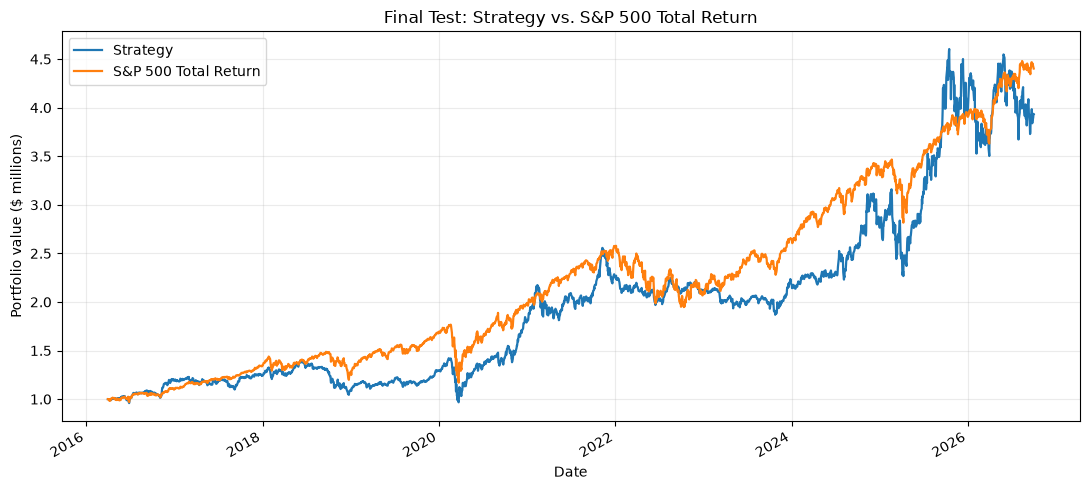

In [70]:
# Part 4: Performance evaluation
# Benchmark: invest $1 million at the first test purchase close.
first_entry = schedule_test["entry_date"].min()

benchmark_prices = (
    benchmark_full.set_index("date")["adj_close"]
    .reindex(test_daily.index)
)
assert benchmark_prices.notna().all()
assert benchmark_prices.gt(0).all()

benchmark_nav = (
    INITIAL_CAPITAL
    * benchmark_prices
    / benchmark_prices.loc[first_entry]
)
benchmark_nav.loc[benchmark_nav.index < first_entry] = INITIAL_CAPITAL

comparison_nav = pd.DataFrame({
    "Strategy": test_daily["nav"],
    "S&P 500 Total Return": benchmark_nav,
})
assert np.isfinite(comparison_nav).all().all()
np.testing.assert_allclose(comparison_nav.iloc[0], INITIAL_CAPITAL)

# Adapted from the lecture backtest's performance calculations.
def performance_metrics(nav):
    returns = nav.pct_change(fill_method=None).dropna()
    years = (nav.index[-1] - nav.index[0]).total_seconds() / (
        365.25 * 24 * 60 * 60
    )
    daily_rf = (1 + RISK_FREE_RATE) ** (1 / 252) - 1
    daily_vol = returns.std(ddof=1)

    return pd.Series({
        "Final value": nav.iloc[-1],
        "Total return": nav.iloc[-1] / nav.iloc[0] - 1,
        "CAGR": (nav.iloc[-1] / nav.iloc[0]) ** (1 / years) - 1,
        "Annualized volatility": daily_vol * np.sqrt(252),
        "Maximum drawdown": (nav / nav.cummax() - 1).min(),
        "Sharpe ratio": (
            np.sqrt(252) * (returns - daily_rf).mean() / daily_vol
            if daily_vol > 1e-12 else np.nan
        ),
    })

performance_table = comparison_nav.apply(performance_metrics)

display(performance_table.style.format({
    column: (
        lambda value: f"${value:,.2f}"
    ) for column in performance_table.columns
}, subset=pd.IndexSlice[["Final value"], :]).format(
    "{:.2%}",
    subset=pd.IndexSlice[[
        "Total return", "CAGR",
        "Annualized volatility", "Maximum drawdown",
    ], :],
).format(
    "{:.3f}", subset=pd.IndexSlice[["Sharpe ratio"], :]
))

import matplotlib.pyplot as plt

ax = (comparison_nav / 1_000_000).plot(
    figsize=(11, 5), linewidth=1.6
)
ax.set_title("Final Test: Strategy vs. S&P 500 Total Return")
ax.set_xlabel("Date")
ax.set_ylabel("Portfolio value ($ millions)")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [71]:
# Audit the corrected result, including converted and acquired lots.
buys = test_trades.loc[
    test_trades["side"].eq("BUY")
].set_index("lot_id")
assert buys.index.is_unique

normal_sales = test_trades.loc[
    test_trades["side"].eq("SELL")
]
buy_dates = normal_sales["lot_id"].map(buys["date"])

assert buy_dates.notna().all()
assert (
    normal_sales["date"]
    >= buy_dates + pd.Timedelta(days=HOLDING_DAYS)
).all()

# Every purchased lot must be either closed once or still open.
closures = test_trades.loc[
    test_trades["side"].isin(["SELL", "CASH_ACQUISITION"])
]
assert not closures["lot_id"].duplicated().any()
assert not test_open_lots["lot_id"].duplicated().any()

closed_ids = set(closures["lot_id"])
open_ids = set(test_open_lots["lot_id"])
assert closed_ids.isdisjoint(open_ids)
assert closed_ids | open_ids == set(buys.index)

realized_pnl = test_trades["realized_pnl"].sum()
open_cost = test_open_lots["entry_cost"].sum()
unrealized_pnl = test_daily.iloc[-1]["holdings_value"] - open_cost

np.testing.assert_allclose(
    test_daily.iloc[-1]["nav"] - INITIAL_CAPITAL,
    realized_pnl + unrealized_pnl,
    rtol=0,
    atol=1e-6,
)

assert np.isfinite(
    test_daily[["cash", "holdings_value", "nav"]]
).all().all()
assert test_daily.index.equals(
    pd.DatetimeIndex(backtest_calendar_test)
)

print("Passed: sale timing, lot reconciliation, and total profit.")
display(pd.Series({
    "Final portfolio value": test_daily.iloc[-1]["nav"],
    "Realized profit": realized_pnl,
    "Unrealized profit": unrealized_pnl,
    "Total transaction fees": test_trades["fee"].sum(),
    "Open lots": len(test_open_lots),
    "Days with stale valuations":
        test_daily["stale_symbols"].map(len).gt(0).sum(),
    "Pending exits at end":
        test_daily.iloc[-1]["pending_exit_lots"],
}).to_frame("value"))

Passed: sale timing, lot reconciliation, and total profit.


,value
Final portfolio value,3.933687e+06
Realized profit,3.004579e+06
Unrealized profit,-7.089186e+04
Total transaction fees,1.247999e+05
Open lots,3.300000e+01
Days with stale valuations,6.000000e+00
Pending exits at end,0.000000e+00


,Strategy,S&P 500 Total Return,Strategy minus benchmark
Year,,,
2016,18.88%,9.78%,9.10%
2017,4.20%,21.83%,-17.63%
2018,-11.70%,-4.38%,-7.31%
2019,18.39%,31.49%,-13.09%
2020,40.22%,18.40%,21.82%
2021,23.96%,28.71%,-4.74%
2022,-6.02%,-18.11%,12.09%
2023,3.70%,26.29%,-22.59%
2024,26.02%,25.02%,1.00%


2016: April–December; 2026: January–September.


,value
Average cash weight,25.60%
Minimum cash weight,0.00%
Maximum cash weight,100.00%
Ending cash weight,44.94%


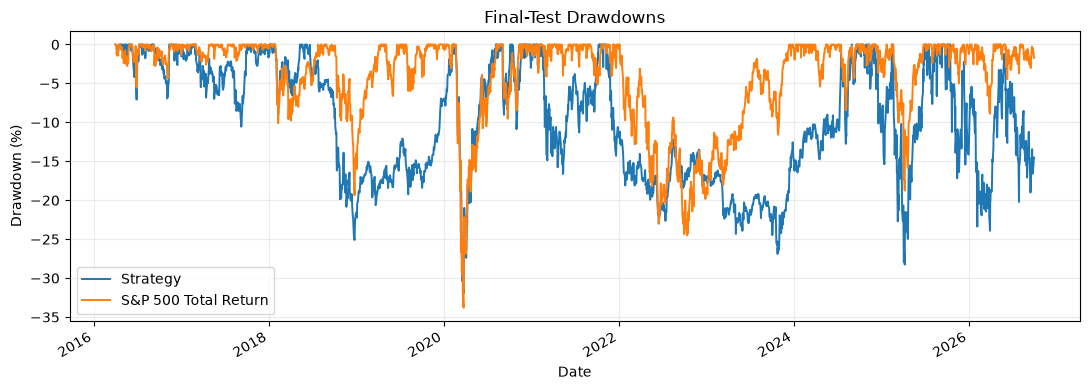

In [72]:
# Calendar-year returns; 2016 and 2026 are partial years.
daily_returns = comparison_nav.pct_change(fill_method=None)

annual_returns = (
    (1 + daily_returns)
    .groupby(daily_returns.index.year)
    .prod() - 1
)
annual_returns.index.name = "Year"
annual_returns["Strategy minus benchmark"] = (
    annual_returns["Strategy"]
    - annual_returns["S&P 500 Total Return"]
)

display(annual_returns.style.format("{:.2%}"))
print("2016: April–December; 2026: January–September.")

cash_fraction = test_daily["cash"] / test_daily["nav"]
display(pd.Series({
    "Average cash weight": cash_fraction.mean(),
    "Minimum cash weight": cash_fraction.min(),
    "Maximum cash weight": cash_fraction.max(),
    "Ending cash weight": cash_fraction.iloc[-1],
}).to_frame("value").style.format("{:.2%}"))

drawdowns = comparison_nav / comparison_nav.cummax() - 1
ax = (100 * drawdowns).plot(figsize=(11, 4), linewidth=1.4)
ax.set_title("Final-Test Drawdowns")
ax.set_xlabel("Date")
ax.set_ylabel("Drawdown (%)")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### Results and interpretation

The final-test portfolio grew from USD 1,000,000 to USD 3,933,687.36,
including remaining holdings valued on September 30, 2026.
The S&P 500 total-return benchmark ended at USD 4,402,746.78.

The strategy earned a 13.93% compound annual return, compared with
15.16% for the benchmark. Annualized volatility was higher
(23.13% versus 17.82%), and its Sharpe ratio was lower
(0.596 versus 0.773), using a 2% annual risk-free rate.
Its maximum drawdown was slightly smaller in magnitude
(-31.95% versus -33.79%). Overall, the strategy did not outperform
the benchmark on either compound return or the Sharpe measure.

Performance varied considerably. The strategy returned 40.22% in
2020 and 42.99% in 2025, but lagged the benchmark substantially in
2017, 2019, and 2023. It lost 6.02% in 2022, compared with the
benchmark's 18.11% loss. The 2016 and 2026 returns cover partial years.

Average daily cash exposure was 25.60%, with cash earning no interest.
This reduced market participation, although a separate attribution
analysis would be needed to quantify its contribution to performance.
Transaction fees totaled approximately $124,800. At the end,
33 lots remained open and no matured exits were pending.

The strategy finished USD 469,059.42 below the benchmark.
Its CAGR was approximately 1.23 percentage points lower.

### Changes I would try next

I would first improve data consistency across ticker changes and
corporate actions, including their effects on model features and
training targets. I would then compare alternative features and
allocation rules using development-period validation, and examine
how cash exposure affected performance. These would be future
experiments, rather than changes selected using the final-test results.

### Data handling and limitations

The simulation uses historical universe membership, next-session
execution, and annual model fitting restricted to completed outcomes.
Preprocessing is fitted on training observations only. Accounting
checks reconcile daily cash, portfolio value, lot closures, and total
profit. These checks establish internal consistency, rather than
independently proving the accuracy of the source data.

Data investigation identified duplicate ticker histories, missing
quotes, ticker changes, cash acquisitions, and a warrant exercise.
Verified aliases were deduplicated for model observations and combined
for position caps. Missing holding prices were supplemented using
successor histories or external observations, with overlap checks.
The RNA overlap contained an October 9, 2024 discrepancy; the original
database observation was retained. Quote repairs were applied to
portfolio valuation and execution, not comprehensively to model
features and training targets.

Corporate-action handling assumes cash is available on the recorded
event date and that CIFRW warrants are exercised cashlessly at the
specified ratio. Fractional units are allowed. These assumptions,
price-series scaling, and incomplete dividend adjustments can affect
the results. The supplied universe also includes securities such as
a note and a warrant, so it is not exclusively common stocks.

Sector classifications are static, and filing-date restrictions do
not guarantee that financial values exclude later restatements.
Missing outcomes are excluded from fitting, which can also introduce
bias. Fixed transaction fees omit bid–ask spreads, market impact,
taxes, and execution uncertainty.

The original development validation selected Ridge alpha = 0.1
before the alias correction. That penalty was retained rather than
retuned after observing test results. The reported performance should
therefore be interpreted as a historical simulation subject to these
data and modeling limitations, not evidence of reliable future
outperformance.